# Mars Data Engine — Phase 0: Setup
**GPU:** T4 (free tier) → Stable Diffusion 1.5, 512×512, fp16, batch size 1 + gradient accumulation, 8-bit Adam.

Run the cells top to bottom. Everything important is saved to Google Drive, so a disconnect never loses finished work.

### Cell 1 — Check the GPU
Confirms Colab gave you a T4 before we install anything. Look for **Tesla T4** and about 15 GB of memory.

In [1]:
# Show which GPU Colab gave us and how much memory it has.
# If this shows no GPU: Runtime -> Change runtime type -> T4 GPU, then re-run.
!nvidia-smi

Tue Nov 24 21:18:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Cell 2 — Install pinned packages
Installs every library for all phases at once, with exact versions so results are reproducible. We keep Colab's own torch/torchvision because they already match its GPU drivers.

⚠️ **After this cell finishes: Runtime → Restart session**, then continue with Cell 3.

In [2]:
# Exact versions = reproducible results. torch/torchvision are NOT reinstalled on purpose.
!pip install -q \
    diffusers==0.43.0 \
    peft==0.22.0 \
    accelerate==1.16.0 \
    transformers==5.24.1 \
    huggingface_hub==2.4.0 \
    timm==1.0.31 \
    torchmetrics==1.9.0 \
    torch-fidelity==0.4.0 \
    open_clip_torch==4.2.2 \
    bitsandbytes==0.50.2 \
    datasets==5.2.0 \
    vendi-score==0.0.3 \
    scikit-learn matplotlib pandas tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


### Cell 3 — Mount Google Drive and create folders
Links your Drive and creates one folder tree for the whole project. Re-running is safe: existing folders are left alone.

In [1]:
from google.colab import drive
from pathlib import Path

# Connect Google Drive so files survive a Colab disconnect.
drive.mount('/content/drive')

# One root folder on Drive for the whole project.
ROOT = Path('/content/drive/MyDrive/mars_data_engine')

# Sub-folders, one per kind of output. exist_ok=True makes this safe to re-run (resumable).
FOLDERS = {
    'data_raw':     ROOT / 'data/raw',                 # downloaded datasets, untouched
    'data_splits':  ROOT / 'data/splits',              # train/val/test lists (CSV)
    'ckpt_cls':     ROOT / 'checkpoints/classifier',   # Phase 2 classifier weights
    'ckpt_lora':    ROOT / 'checkpoints/lora',         # Phase 3 LoRA weights
    'gen_raw':      ROOT / 'generated/raw',            # Phase 4 all generated images
    'gen_filtered': ROOT / 'generated/filtered',       # Phase 4 images that passed the filter
    'old_images':   ROOT / 'old_project_images',       # your images from the PDF project
    'results':      ROOT / 'results',                  # metrics, tables, plots
    'run_configs':  ROOT / 'run_configs',              # one JSON of settings per run
    'code':         ROOT / 'code',                     # shared helper code
}
for path in FOLDERS.values():
    path.mkdir(parents=True, exist_ok=True)

print('Project root:', ROOT)
for name, path in FOLDERS.items():
    print(f'  {name:13s} -> {path}')

Mounted at /content/drive
Project root: /content/drive/MyDrive/mars_data_engine
  data_raw      -> /content/drive/MyDrive/mars_data_engine/data/raw
  data_splits   -> /content/drive/MyDrive/mars_data_engine/data/splits
  ckpt_cls      -> /content/drive/MyDrive/mars_data_engine/checkpoints/classifier
  ckpt_lora     -> /content/drive/MyDrive/mars_data_engine/checkpoints/lora
  gen_raw       -> /content/drive/MyDrive/mars_data_engine/generated/raw
  gen_filtered  -> /content/drive/MyDrive/mars_data_engine/generated/filtered
  old_images    -> /content/drive/MyDrive/mars_data_engine/old_project_images
  results       -> /content/drive/MyDrive/mars_data_engine/results
  run_configs   -> /content/drive/MyDrive/mars_data_engine/run_configs
  code          -> /content/drive/MyDrive/mars_data_engine/code


### Cell 4 — Shared helper code (seeds + run logging)
Saves a small helper file to Drive that every later phase imports: one function fixes random seeds, one logs all run settings to JSON, and two mark a phase as finished so we can skip it after a disconnect.

In [2]:
# Write a helper file to Drive so seeding and logging work the same way in every phase.
helper_code = r'''
import json, os, random, platform, datetime
import numpy as np
import torch

def set_seed(seed: int):
    """Fix all random number generators so a run can be repeated exactly."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Deterministic cuDNN algorithms: slightly slower, but repeatable.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

def save_run_config(config: dict, folder, run_name: str):
    """Save every setting of a run (seed, steps, guidance scale, LoRA rank...) to a JSON file."""
    import importlib.metadata as md
    config = dict(config)  # copy so we don't change the caller's dict
    config["run_name"] = run_name
    config["timestamp"] = datetime.datetime.now().isoformat(timespec="seconds")
    config["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
    config["python"] = platform.python_version()
    # Record library versions so results can be reproduced later.
    pkgs = ["torch", "torchvision", "diffusers", "peft", "accelerate", "transformers",
            "timm", "torchmetrics", "open_clip_torch"]
    config["versions"] = {}
    for p in pkgs:
        try:
            config["versions"][p] = md.version(p)
        except md.PackageNotFoundError:
            config["versions"][p] = "not installed"
    path = os.path.join(str(folder), f"{run_name}.json")
    with open(path, "w") as f:
        json.dump(config, f, indent=2)
    print("Saved run config ->", path)
    return path

def phase_done(root, phase: str) -> bool:
    """True if a phase already finished (a marker file exists)."""
    return os.path.exists(os.path.join(str(root), f".done_{phase}"))

def mark_phase_done(root, phase: str):
    """Write a marker file saying this phase finished successfully."""
    open(os.path.join(str(root), f".done_{phase}"), "w").close()
'''

(FOLDERS['code'] / 'mars_utils.py').write_text(helper_code)

# Let Python find the helper file, then import it.
import sys
sys.path.append(str(FOLDERS['code']))
import mars_utils
print('Helper file saved and imported OK.')

Helper file saved and imported OK.


### Cell 5 — Sanity check and log the environment
Checks that the GPU and every library load, then writes the T4 settings and library versions to `run_configs/phase0_environment.json` on Drive.

In [3]:
import torch, diffusers, peft, timm, torchmetrics, open_clip

mars_utils.set_seed(42)

# Basic GPU facts.
assert torch.cuda.is_available(), 'No GPU found! Change the runtime type to T4.'
gpu_name = torch.cuda.get_device_name(0)
total_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'GPU: {gpu_name}  |  memory: {total_gb:.1f} GB')

# Global settings sized for a T4. Later phases will read these.
T4_SETTINGS = {
    'seed': 42,
    'resolution': 512,           # SD 1.5's native size
    'sd_model': 'stable-diffusion-v1-5/stable-diffusion-v1-5',  # community mirror of SD 1.5
    'mixed_precision': 'fp16',   # T4 has no bf16 support
    'lora_train_batch_size': 1,  # T4-safe
    'grad_accumulation': 4,      # effective batch size = 1 x 4 = 4
    'use_8bit_adam': True,       # saves several GB of GPU memory
    'gen_batch_size': 4,         # images generated at once in Phase 4
    'classifier_batch_size': 64, # ResNet-50 / ConvNeXt-Tiny at 224px
}
mars_utils.save_run_config(T4_SETTINGS, FOLDERS['run_configs'], 'phase0_environment')
mars_utils.mark_phase_done(ROOT, 'phase0')
print('Phase 0 complete.')

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


GPU: Tesla T4  |  memory: 15.6 GB
Saved run config -> /content/drive/MyDrive/mars_data_engine/run_configs/phase0_environment.json
Phase 0 complete.


In [4]:
# Show the settings + library versions we just logged, to confirm the file on Drive is correct.
import json
print(json.dumps(json.load(open(FOLDERS['run_configs'] / 'phase0_environment.json')), indent=2))

{
  "seed": 42,
  "resolution": 512,
  "sd_model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "mixed_precision": "fp16",
  "lora_train_batch_size": 1,
  "grad_accumulation": 4,
  "use_8bit_adam": true,
  "gen_batch_size": 4,
  "classifier_batch_size": 64,
  "run_name": "phase0_environment",
  "timestamp": "2026-11-24T21:22:05",
  "gpu": "Tesla T4",
  "python": "3.13.16",
  "versions": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "diffusers": "0.43.0",
    "peft": "0.22.0",
    "accelerate": "1.16.0",
    "transformers": "5.24.1",
    "timm": "1.0.31",
    "torchmetrics": "1.9.0",
    "open_clip_torch": "4.2.2"
  }
}


### ✅ Before moving to Phase 1, check:
1. Cell 1 shows **Tesla T4**.
2. Cell 5 prints `GPU: Tesla T4 | memory: ~15.6 GB` and `Phase 0 complete.`
3. In Drive, `MyDrive/mars_data_engine/` has all sub-folders and `run_configs/phase0_environment.json`.

**After any disconnect:** re-run Cell 2 → restart session → Cells 3–4. Nothing on Drive is lost.

# Phase 1 — Real data
**Dataset:** DoMars16k from Mars-Bench, hosted on Hugging Face as **Mirali33/mb-domars16k** (CC-BY-4.0).
16,150 image tiles, 200×200 px, grayscale, 15 expert-labelled landform classes, with official train / val / test splits.

⚠️ These tiles come from **CTX** (Context Camera, ~6 m/pixel), not HiRISE (~0.25–0.5 m/pixel). So later captions should say "CTX orbital image", and our generated images will look like CTX.

### Cell 6 — Resume cell
Reconnects Drive and loads the helper code, so Phase 1 can be run on its own after a disconnect.

In [10]:
# Safe to run any time: reconnect Drive, set paths, import our helpers.
from google.colab import drive
drive.mount('/content/drive')

import sys, json, io
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/mars_data_engine')
sys.path.append(str(ROOT / 'code'))
import mars_utils

DATA_DIR    = ROOT / 'data/raw/mb-domars16k'   # where the dataset will live on Drive
SPLITS_DIR  = ROOT / 'data/splits'
RESULTS_DIR = ROOT / 'results'
CONFIG_DIR  = ROOT / 'run_configs'
mars_utils.set_seed(42)
print('Ready. Phase 0 done?', mars_utils.phase_done(ROOT, 'phase0'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ready. Phase 0 done? True


### Cell 7 — Download DoMars16k to Drive
Downloads the dataset files (about 230 MB) from Hugging Face into your Drive, and skips the download if they are already there. It also records the exact dataset version (commit hash), so the paper can cite the exact data used.

In [11]:
from huggingface_hub import snapshot_download, HfApi

REPO_ID = 'Mirali33/mb-domars16k'
dataset_version = HfApi().dataset_info(REPO_ID).sha   # exact commit of the dataset

test_file = DATA_DIR / 'data' / 'test-00000-of-00001.parquet'
if test_file.exists():
    print('Already downloaded - skipping.')
else:
    snapshot_download(repo_id=REPO_ID, repo_type='dataset',
                      revision=dataset_version, local_dir=str(DATA_DIR))
    print('Downloaded to', DATA_DIR)

for f in sorted((DATA_DIR / 'data').glob('*.parquet')):
    print(f'{f.name:60s} {f.stat().st_size/1e6:6.1f} MB')
print('Dataset version (commit):', dataset_version)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 20 files:   0%|          | 0/20 [00:00<?, ?it/s]

Downloaded to /content/drive/MyDrive/mars_data_engine/data/raw/mb-domars16k
few_shot_train_10_shot-00000-of-00001.parquet                   1.1 MB
few_shot_train_15_shot-00000-of-00001.parquet                   1.7 MB
few_shot_train_1_shot-00000-of-00001.parquet                    0.1 MB
few_shot_train_20_shot-00000-of-00001.parquet                   2.3 MB
few_shot_train_2_shot-00000-of-00001.parquet                    0.2 MB
few_shot_train_5_shot-00000-of-00001.parquet                    0.6 MB
partition_train_0.01x_partition-00000-of-00001.parquet          0.9 MB
partition_train_0.02x_partition-00000-of-00001.parquet          1.8 MB
partition_train_0.05x_partition-00000-of-00001.parquet          4.3 MB
partition_train_0.10x_partition-00000-of-00001.parquet          8.7 MB
partition_train_0.20x_partition-00000-of-00001.parquet         17.3 MB
partition_train_0.25x_partition-00000-of-00001.parquet         21.5 MB
partition_train_0.50x_partition-00000-of-00001.parquet         43.2 MB
t

### Cell 8 — Load the splits and count images per class
Reads the official train / val / test files and builds a table of how many images each class has. After counting, we delete the test images from memory so we can't use them by accident.

In [12]:
import pandas as pd

# mapping.json links label numbers to short codes and full names, e.g. 13 -> ("cra", "Crater")
class_info = json.load(open(DATA_DIR / 'mapping.json'))
ID2CODE = {int(k): v[0] for k, v in class_info.items()}
ID2NAME = {int(k): v[1] for k, v in class_info.items()}

def load_split(name):
    """Each split is one parquet file with two columns: image (PNG/JPG bytes) and label (0-14)."""
    return pd.read_parquet(DATA_DIR / 'data' / f'{name}-00000-of-00001.parquet')

splits = {s: load_split(s) for s in ['train', 'val', 'test']}

counts = pd.DataFrame({s: df['label'].value_counts().sort_index() for s, df in splits.items()})
counts = counts.fillna(0).astype(int)
counts.index = [f'{ID2CODE[i]} - {ID2NAME[i]}' for i in counts.index]
counts['total'] = counts.sum(axis=1)
counts.loc['ALL CLASSES'] = counts.sum()
counts.to_csv(RESULTS_DIR / 'phase1_class_counts.csv')
display(counts)

# Lock the test set: remove it from memory. We only touch it again in Phase 6.
n_test = len(splits['test'])
del splits['test']
print('Test images (locked until Phase 6):', n_test)

,train,val,test,total
ael - Aeolian Straight,711,203,102,1016
rou - Rough Terrain,705,201,101,1007
cli - Cliff,700,200,100,1000
aec - Aeolian Curved,741,211,106,1058
tex - Textured Terrain,732,209,105,1046
smo - Smooth Terrain,811,232,116,1159
fss - Mass Wasting,752,215,107,1074
rid - Ridge,713,203,102,1018
fse - Slope Streaks,751,215,107,1073
sfe - Mounds,704,201,100,1005


Test images (locked until Phase 6): 1614


### Cell 9 — Map DoMars16k classes to my 8 terrain classes
Shows, honestly, which of your 8 classes have a real-data match. Only classes with real images can be used for LoRA fine-tuning, filtering, and the downstream test. The mapping is saved to Drive for later phases.

In [13]:
# quality: 'direct' = same landform; 'approximate' = related but not the same thing; 'none' = no real data here
MAPPING = {
    'craters':                      {'codes': ['cra'],        'quality': 'direct',
        'note': 'Crater. (sfx = Crater Field, many small craters, is kept as its own class.)'},
    'cliffs':                       {'codes': ['cli'],        'quality': 'direct', 'note': 'Cliff.'},
    'ridges':                       {'codes': ['rid'],        'quality': 'direct', 'note': 'Ridge.'},
    'sand dunes':                   {'codes': ['ael', 'aec'], 'quality': 'direct',
        'note': 'Aeolian Straight + Aeolian Curved = wind-formed dunes and ripples.'},
    'rock fields':                  {'codes': ['rou'],        'quality': 'approximate',
        'note': 'Rough Terrain is the closest; at CTX resolution single boulders are not visible.'},
    'volcanic plains':              {'codes': ['smo'],        'quality': 'approximate',
        'note': 'Smooth Terrain only. Not labelled as volcanic - smooth plains can also be sedimentary or dusty.'},
    'subsurface cavities':          {'codes': [],             'quality': 'none',
        'note': 'No pit / skylight / lava-tube class in DoMars16k.'},
    'layered sedimentary deposits': {'codes': [],             'quality': 'none',
        'note': 'No layered-deposit class in DoMars16k.'},
}

CODE2ID = {c: i for i, c in ID2CODE.items()}
rows = []
for my_class, m in MAPPING.items():
    n_train = int(splits['train']['label'].isin([CODE2ID[c] for c in m['codes']]).sum())
    rows.append({'my class': my_class, 'DoMars16k codes': ', '.join(m['codes']) or '-',
                 'match': m['quality'], 'train images': n_train, 'note': m['note']})
mapping_table = pd.DataFrame(rows)
display(mapping_table)

json.dump({'mapping': MAPPING, 'id2code': ID2CODE, 'id2name': ID2NAME},
          open(SPLITS_DIR / 'class_mapping.json', 'w'), indent=2)
print('Saved ->', SPLITS_DIR / 'class_mapping.json')

,my class,DoMars16k codes,match,train images,note
0,craters,cra,direct,815,"Crater. (sfx = Crater Field, many small crater..."
1,cliffs,cli,direct,700,Cliff.
2,ridges,rid,direct,713,Ridge.
3,sand dunes,"ael, aec",direct,1452,Aeolian Straight + Aeolian Curved = wind-forme...
4,rock fields,rou,approximate,705,Rough Terrain is the closest; at CTX resolutio...
5,volcanic plains,smo,approximate,811,Smooth Terrain only. Not labelled as volcanic ...
6,subsurface cavities,-,none,0,No pit / skylight / lava-tube class in DoMars16k.
7,layered sedimentary deposits,-,none,0,No layered-deposit class in DoMars16k.


Saved -> /content/drive/MyDrive/mars_data_engine/data/splits/class_mapping.json


### Cell 10 — Check for data leakage and lock the test set
Each tile is cut from a larger CTX image (a "product"). If tiles from the same product appear in both train and test, test scores can look better than they really are, so we measure this overlap. We also save a fingerprint (SHA-256 hash) of the test file, so later phases can confirm it was never changed.

In [14]:
import hashlib

# annotation.csv lists every tile's file name and split. The CTX product ID is the part before "_CX".
ann = pd.read_csv(DATA_DIR / 'annotation.csv')
ann['ctx_product'] = ann['file_id'].str.split('_CX').str[0]
print(ann['split'].value_counts().to_string(), '\n')

products = {s: set(ann.loc[ann['split'] == s, 'ctx_product']) for s in ['train', 'val', 'test']}
shared = products['test'] & products['train']
test_rows = ann[ann['split'] == 'test']
share_tiles = test_rows['ctx_product'].isin(products['train']).mean()

leakage = {
    'ctx_products_train': len(products['train']),
    'ctx_products_test': len(products['test']),
    'test_products_also_in_train': len(shared),
    'fraction_test_tiles_from_train_products': round(float(share_tiles), 3),
}
print(json.dumps(leakage, indent=2))

# Fingerprint of the test file. If this hash ever changes, the test set was modified.
test_path = DATA_DIR / 'data' / 'test-00000-of-00001.parquet'
lock = {'test_file': str(test_path),
        'sha256': hashlib.sha256(test_path.read_bytes()).hexdigest(),
        'n_images': n_test,
        'rule': 'Do not train, tune, or pick models on this file until Phase 6.',
        'leakage_check': leakage}
json.dump(lock, open(SPLITS_DIR / 'test_lock.json', 'w'), indent=2)
print('Saved ->', SPLITS_DIR / 'test_lock.json')

split
train    11305
val       3231
test      1614 

{
  "ctx_products_train": 163,
  "ctx_products_test": 148,
  "test_products_also_in_train": 148,
  "fraction_test_tiles_from_train_products": 1.0
}
Saved -> /content/drive/MyDrive/mars_data_engine/data/splits/test_lock.json


### Cell 10b — Build a leakage-free split (grouped by CTX image)
The check above shows that **100% of official test tiles come from CTX images that also appear in train**. Neighbouring tiles from one CTX image look very alike, so test scores would be too optimistic. This matters a lot for us: the LoRA learns from train tiles, so the generated images would also "know" the test images.

Here we re-split all 16,150 tiles so that **each CTX image belongs to exactly one split** (about 72% train / 14% val / 14% test, class-balanced). This "geo split" is our main split. The official split is kept only to compare with Mars-Bench numbers.

In [19]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# 1) Give every parquet row its file name and CTX image ID.
#    annotation.csv lists tiles in the same order as the parquet files (we check this with assert).
parts = []
for s in ['train', 'val', 'test']:
    a = ann[ann['split'] == s].reset_index(drop=True)
    parquet_labels = pd.read_parquet(DATA_DIR / 'data' / f'{s}-00000-of-00001.parquet', columns=['label'])['label'].values
    assert (a['label'].values == parquet_labels).all(), f'Row order mismatch in {s}!'
    a['source_file'] = s            # which official parquet file the image is in
    a['row'] = np.arange(len(a))    # row number inside that file
    parts.append(a)
all_tiles = pd.concat(parts, ignore_index=True)

# 2) Split by CTX image. A few CTX images hold hundreds of tiles, so one random grouping can be
#    badly unbalanced. We try many seeds and keep the most class-balanced split.
#    This only looks at labels and image IDs - never at image content - so it is fair.
N_FOLDS = 7          # each fold ~ 1/7 = 14% of the data; one fold -> test, one -> val, rest -> train
MIN_PER_CLASS = 60   # every class should have at least this many val AND test images
y, groups = all_tiles['label'].values, all_tiles['ctx_product'].values
class_totals = np.bincount(y, minlength=15)

def balance_score(test_idx, val_idx):
    """Lower = better. Distance of each class's val/test share from 1/7, plus a big penalty for thin classes."""
    t = np.bincount(y[test_idx], minlength=15); v = np.bincount(y[val_idx], minlength=15)
    score = np.abs(t / class_totals - 1 / N_FOLDS).sum() + np.abs(v / class_totals - 1 / N_FOLDS).sum()
    return score + 10 * ((t < MIN_PER_CLASS).sum() + (v < MIN_PER_CLASS).sum())

best = (np.inf, None)
for seed in range(150):
    folds = [held for _, held in StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=seed).split(y, y, groups)]
    for i in range(N_FOLDS):
        for j in range(N_FOLDS):
            if i != j:
                s = balance_score(folds[i], folds[j])
                if s < best[0]:
                    best = (s, (seed, folds[i], folds[j]))
best_score, (best_seed, test_idx, val_idx) = best
print(f'Best seed: {best_seed}  |  balance score: {best_score:.3f} (0 = perfect)')

all_tiles['geo_split'] = 'train'
all_tiles.loc[all_tiles.index[val_idx], 'geo_split'] = 'val'
all_tiles.loc[all_tiles.index[test_idx], 'geo_split'] = 'test'

# 3) Check: no CTX image may appear in two splits.
prod_sets = {s: set(all_tiles.loc[all_tiles['geo_split'] == s, 'ctx_product']) for s in ['train', 'val', 'test']}
assert not (prod_sets['train'] & prod_sets['test']) and not (prod_sets['train'] & prod_sets['val']) \
       and not (prod_sets['val'] & prod_sets['test']), 'Leakage found!'
print('No CTX image is shared between splits.')

geo_counts = pd.crosstab(all_tiles['feature_name'].map(lambda c: f'{c} - {ID2NAME[CODE2ID[c]]}'),
                         all_tiles['geo_split'])[['train', 'val', 'test']]
geo_counts['total'] = geo_counts.sum(axis=1)
geo_counts.loc['ALL CLASSES'] = geo_counts.sum()
display(geo_counts)
thin = geo_counts.drop('ALL CLASSES').query('test < 50').index.tolist()
print('Classes with fewer than 50 test images (results for these will be noisy):', thin or 'none')
geo_seed_info = {'search_seeds': 150, 'best_seed': int(best_seed), 'balance_score': round(float(best_score), 3)}

# 4) Save the split and lock its test part with a fingerprint.
all_tiles.to_csv(SPLITS_DIR / 'geo_split.csv', index=False)
test_ids = '\n'.join(sorted(all_tiles.loc[all_tiles['geo_split'] == 'test', 'file_id']))
lock = json.load(open(SPLITS_DIR / 'test_lock.json'))
lock['geo_split'] = {'file': str(SPLITS_DIR / 'geo_split.csv'),
                     'test_ids_sha256': hashlib.sha256(test_ids.encode()).hexdigest(),
                     'n_test': int((all_tiles['geo_split'] == 'test').sum()),
                     'n_ctx_images': {s: len(p) for s, p in prod_sets.items()},
                     'split_search': geo_seed_info,
                     'rule': 'Main test set. Do not train, tune, or pick models on it until Phase 6.'}
json.dump(lock, open(SPLITS_DIR / 'test_lock.json', 'w'), indent=2)
print('Saved ->', SPLITS_DIR / 'geo_split.csv')
print('CTX images per split:', lock['geo_split']['n_ctx_images'])

Best seed: 123  |  balance score: 2.011 (0 = perfect)
No CTX image is shared between splits.


geo_split,train,val,test,total
feature_name,,,,
aec - Aeolian Curved,645,168,245,1058
ael - Aeolian Straight,629,79,308,1016
cli - Cliff,786,108,106,1000
cra - Crater,879,156,129,1164
fse - Slope Streaks,512,272,289,1073
fsf - Channel,888,146,138,1172
fsg - Gullies,657,100,245,1002
fss - Mass Wasting,883,117,74,1074
mix - Mixed Terrain,489,418,107,1014


Classes with fewer than 50 test images (results for these will be noisy): none
Saved -> /content/drive/MyDrive/mars_data_engine/data/splits/geo_split.csv
CTX images per split: {'train': 115, 'val': 21, 'test': 27}


### Cell 11 — Show sample images per class
Draws 6 random training images per class, so you can see what each label looks like. The figure is also saved to Drive.

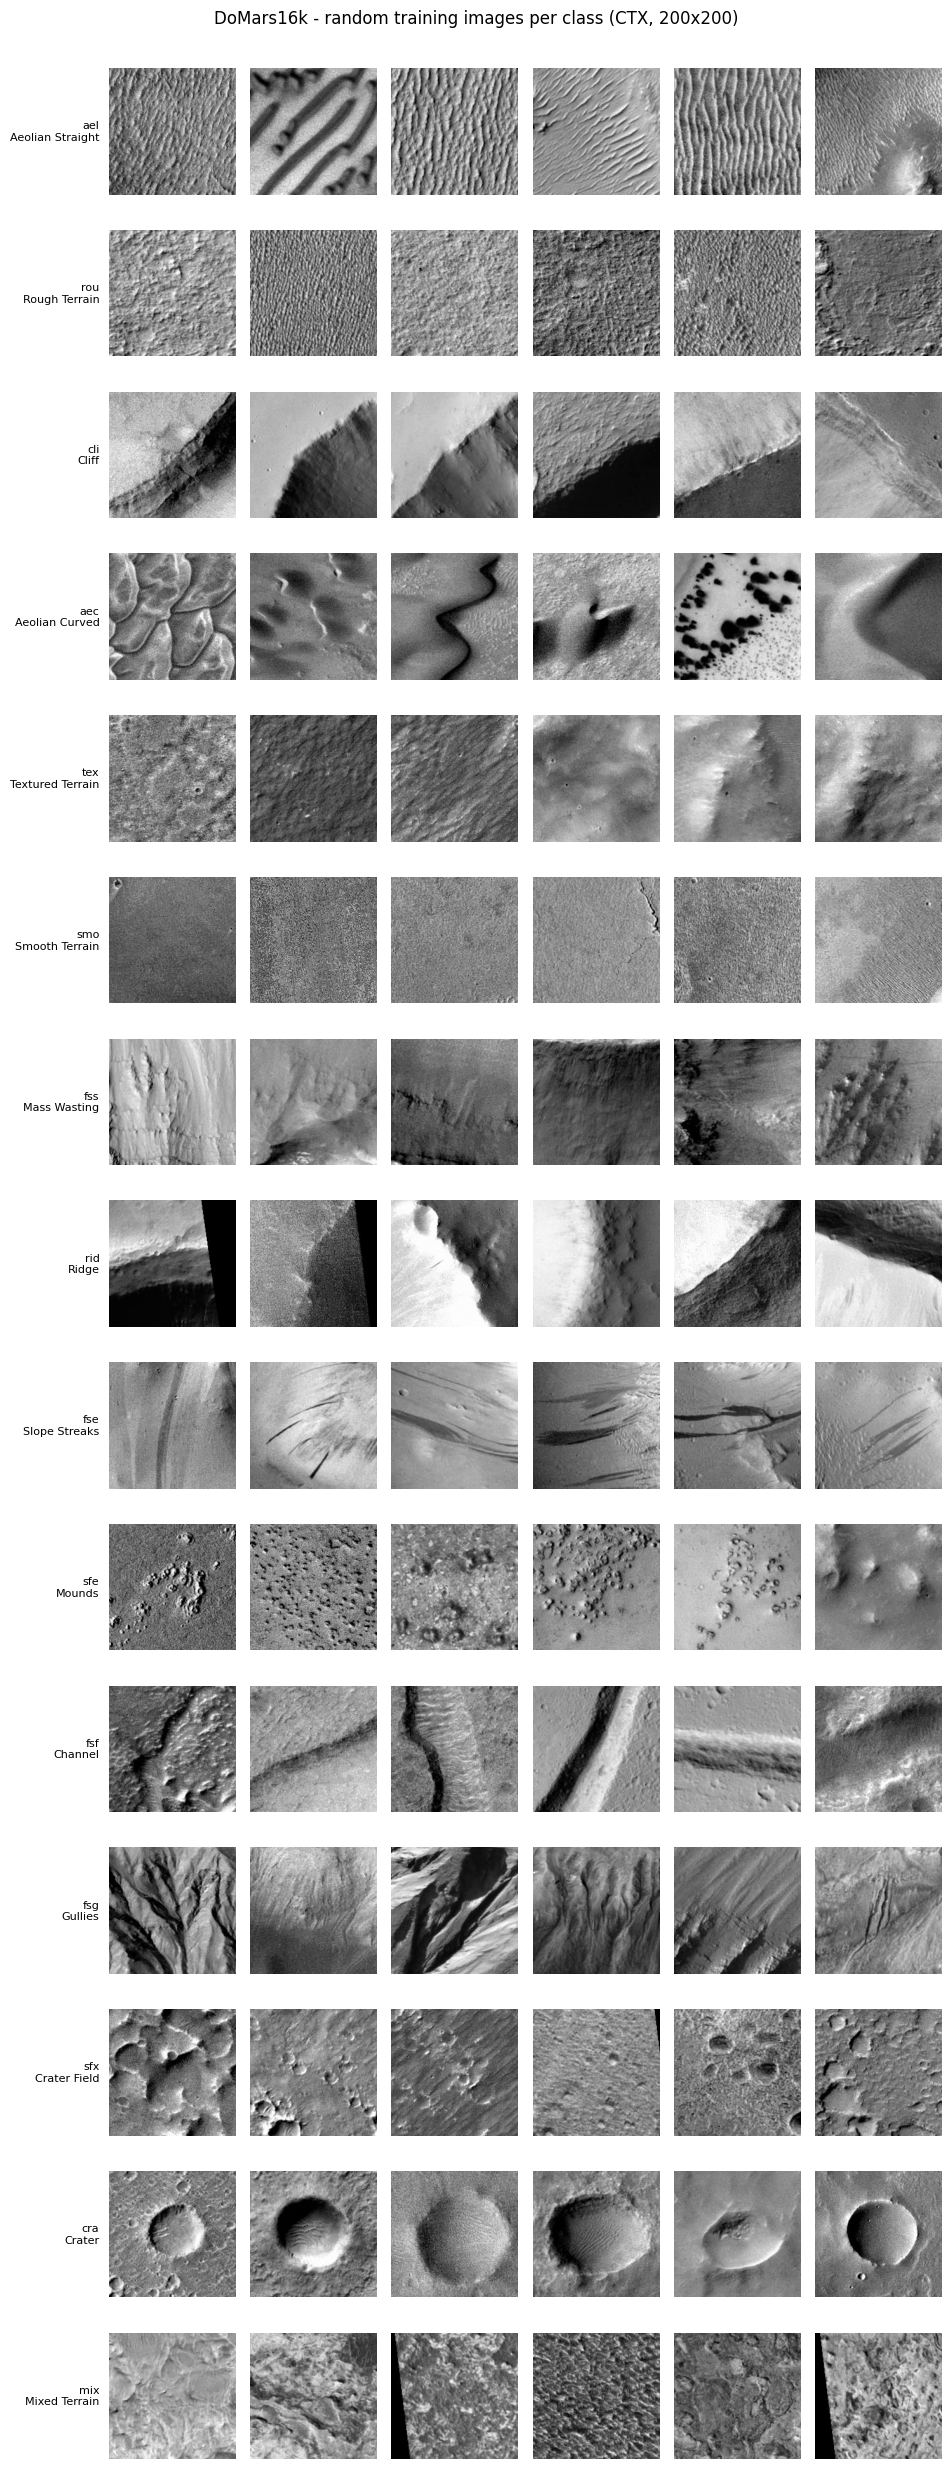

Saved -> /content/drive/MyDrive/mars_data_engine/results/phase1_samples_per_class.png


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

rng = np.random.default_rng(42)     # fixed seed -> same samples every time
N_SHOW = 6
train = splits['train']
class_ids = sorted(ID2CODE)

fig, axes = plt.subplots(len(class_ids), N_SHOW, figsize=(N_SHOW * 1.6, len(class_ids) * 1.65))
for row, cid in enumerate(class_ids):
    idx = rng.choice(np.where(train['label'].values == cid)[0], size=N_SHOW, replace=False)
    for col, i in enumerate(idx):
        img = Image.open(io.BytesIO(train.iloc[i]['image']['bytes']))
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].axis('off')
    # class name on the left of each row
    axes[row, 0].text(-15, 100, f'{ID2CODE[cid]}\n{ID2NAME[cid]}', ha='right', va='center', fontsize=8)

plt.suptitle('DoMars16k - random training images per class (CTX, 200x200)', y=1.0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'phase1_samples_per_class.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved ->', RESULTS_DIR / 'phase1_samples_per_class.png')

### Cell 12 — Write project notes and finish Phase 1
Saves the run settings to JSON and writes a running notes file, **PROJECT_NOTES.md**, in your Drive project folder. Each phase adds its own section, so the notes always match what was actually run. You can paste from it into your paper.

In [23]:
NOTES_DIR = ROOT / 'notes'
NOTES_DIR.mkdir(exist_ok=True)

def md_table(df):
    """Turn a small pandas table into a Markdown table (no extra libraries needed)."""
    df = df.reset_index() if df.index.name or not isinstance(df.index, pd.RangeIndex) else df
    head = '| ' + ' | '.join(map(str, df.columns)) + ' |'
    sep = '|' + '---|' * len(df.columns)
    body = ['| ' + ' | '.join(map(str, r)) + ' |' for r in df.values]
    return '\n'.join([head, sep] + body)

def write_note(name, text):
    """Save one phase's notes, then rebuild PROJECT_NOTES.md from all phase notes in order."""
    (NOTES_DIR / f'{name}.md').write_text(text.strip() + '\n')
    parts = [p.read_text() for p in sorted(NOTES_DIR.glob('phase*.md'))]
    (ROOT / 'PROJECT_NOTES.md').write_text('# Mars Data Engine - Project Notes\n\n' + '\n\n'.join(parts))

env = json.load(open(CONFIG_DIR / 'phase0_environment.json'))
write_note('phase0', f"""
## Phase 0 - Setup ({env['timestamp'][:10]})
- GPU: {env['gpu']} (Colab free tier). Settings: SD 1.5 at 512x512, fp16, LoRA batch 1 x grad-accum 4, 8-bit Adam.
- Libraries: {', '.join(f'{k} {v}' for k, v in env['versions'].items())}. Python {env['python']}.
- Global seed 42. All outputs saved under MyDrive/mars_data_engine/.
- Note: pip warned about cudf/pyarrow and diffusers disabled torchao; neither is used, so both are harmless.
""")

write_note('phase1', f"""
## Phase 1 - Real data
- Dataset: DoMars16k (Mars-Bench), Hugging Face Mirali33/mb-domars16k, commit {dataset_version}, CC-BY-4.0.
- 16,150 CTX tiles (~6 m/px), 200x200 grayscale, 15 classes.
- Official Mars-Bench splits kept only for comparison. Main experiments use our leakage-free geo split (below).
- Important: imagery is CTX, not HiRISE. Captions and claims must say CTX.

### Images per class (official Mars-Bench split)
{md_table(counts)}

### Mapping to my 8 terrain classes (train images = official train split)
{md_table(mapping_table)}

- Direct matches: craters, cliffs, ridges, sand dunes. Approximate: rock fields (rough terrain), volcanic plains (smooth terrain).
- No real data in DoMars16k for: subsurface cavities, layered sedimentary deposits. These need another source, or must be left out of the downstream test.

### Leakage check on the official split
{json.dumps(leakage)}
- Every official test tile comes from a CTX image that also has tiles in train. Test scores on the official split are therefore optimistic, and a LoRA trained on train tiles would have seen the same CTX scenes as the test set.

### Leakage-free geo split (MAIN split for this project)
- All 16,150 tiles re-split so each CTX image is in exactly one split (StratifiedGroupKFold, 7 folds; best of {geo_seed_info['search_seeds']} seeds by class balance -> seed {geo_seed_info['best_seed']}).
- CTX images per split: {lock['geo_split']['n_ctx_images']}. Verified: no CTX image shared between splits.

{md_table(geo_counts)}

- Class shares per split are uneven because some CTX images hold hundreds of tiles of one class. Report macro-F1 and per-class F1, not only accuracy.

### Test-set lock
- Fingerprints of the official test file and of the geo-split test IDs saved in data/splits/test_lock.json. Neither test set is used until Phase 6.

### Decisions / open questions
- Phase 2 baseline: pick the model on the geo VAL set. Test-set numbers are computed once, in Phase 6, with all other runs.
- Phase 3 captions must say CTX, not HiRISE. LoRA trains on geo-train tiles only, upscaled from 200 px to 512 px.
- Generate only classes with real data: direct (craters, cliffs, ridges, sand dunes) and, marked approximate, rock fields and volcanic plains.
- Mars-Bench also ships official low-data partitions (1%, 2%, 5%, 10%, 20%, 25%, 50% of train) - planned for Phase 6.
""")

mars_utils.save_run_config({'phase': 1, 'dataset': REPO_ID, 'dataset_commit': dataset_version,
                            'seed': 42, 'n_test_locked': n_test, 'leakage': leakage,
                            'geo_split': lock['geo_split']},
                           CONFIG_DIR, 'phase1_data')
mars_utils.mark_phase_done(ROOT, 'phase1')
print((ROOT / 'PROJECT_NOTES.md').read_text()[:1500])
print('...\nPhase 1 complete.')

Saved run config -> /content/drive/MyDrive/mars_data_engine/run_configs/phase1_data.json
# Mars Data Engine - Project Notes

## Phase 0 - Setup (2026-11-24)
- GPU: Tesla T4 (Colab free tier). Settings: SD 1.5 at 512x512, fp16, LoRA batch 1 x grad-accum 4, 8-bit Adam.
- Libraries: torch 2.14.1+cu130, torchvision 0.29.1+cu130, diffusers 0.43.0, peft 0.22.0, accelerate 1.16.0, transformers 5.24.1, timm 1.0.31, torchmetrics 1.9.0, open_clip_torch 4.2.2. Python 3.13.16.
- Global seed 42. All outputs saved under MyDrive/mars_data_engine/.
- Note: pip warned about cudf/pyarrow and diffusers disabled torchao; neither is used, so both are harmless.


## Phase 1 - Real data
- Dataset: DoMars16k (Mars-Bench), Hugging Face Mirali33/mb-domars16k, commit 4d79cf7a0fc98fab76d436f6434e4ce3eb78cd85, CC-BY-4.0.
- 16,150 CTX tiles (~6 m/px), 200x200 grayscale, 15 classes.
- Official Mars-Bench splits kept only for comparison. Main experiments use our leakage-free geo split (below).
- Important: imagery is

### ✅ Phase 1 checklist (before Phase 2)
1. Cell 8 table: 16,150 images, 15 classes, roughly 1,000 per class.
2. Cell 10: the official split leaks (every test CTX image is also in train). Cell 10b prints **No CTX image is shared between splits** and every class has at least 65 val and test images.
3. Cell 11 sample grid looks right (craters round, dunes rippled, gullies as channels on slopes).
4. On Drive: data/splits/geo_split.csv, class_mapping.json, test_lock.json, results/phase1_samples_per_class.png, and **PROJECT_NOTES.md** in the project folder.

**After a disconnect:** re-run Cell 2 → restart session → Cell 6 onward. The download is skipped if the files are already on Drive.

# GitHub sync — save the project to github.com/guptuv/Mars-Terrain-Diffusion
At the end of every phase we push the project to GitHub as **one commit per phase**, so the repo keeps a clean history of the work.

What goes to GitHub: this notebook, the helper code, the notes (PROJECT_NOTES.md), run configs (JSON), split files, and result tables and plots.
What stays only on Drive: the raw dataset, model checkpoints, and generated images. They are too big for GitHub, and the dataset belongs to its authors.

**One-time setup (you do this — Claude never sees your token):**
1. GitHub → Settings → Developer settings → Fine-grained tokens → *Generate new token*. Repository access: **only Mars-Terrain-Diffusion**. Permissions: **Contents → Read and write**.
2. In Colab, click the 🔑 **Secrets** icon on the left → *Add new secret* → name **GITHUB_TOKEN**, paste the token, and switch **Notebook access** on.

### Cell 13 — Write the GitHub sync helper
Saves a small helper file to Drive. It clones the repo into temporary Colab storage, copies the project files in, makes a commit, and pushes. The token is read from Colab Secrets and is never written to Drive or printed.

In [24]:
sync_code = r'''
import shutil, subprocess, datetime, base64
from pathlib import Path

REPO = "guptuv/Mars-Terrain-Diffusion"
REPO_URL = "https://github.com/" + REPO + ".git"
NOTEBOOK = Path("/content/drive/MyDrive/Colab Notebooks/Mars_Data_Engine.ipynb")
AUTHOR_NAME, AUTHOR_EMAIL = "Yuvraj Gupta", "guptuv" + chr(64) + "users.noreply.github.com"
TRAILER = "\n\nCo-Authored-By: Claude Opus 5.5 <noreply" + chr(64) + "anthropic.com>"
WORK = Path("/content/_github_sync")      # temporary clone (not on Drive)
MAX_MB = 20                                 # skip any single file bigger than this
BT = chr(96) * 3                            # three backticks, for code blocks in the README

PHASES = [("phase0", "Setup: GPU, pinned libraries, Drive layout, seeds, run logging"),
          ("phase1", "Real data: DoMars16k, class mapping, leakage check, CTX-grouped split"),
          ("phase2", "Baseline classifier (real data only)"),
          ("phase3", "LoRA fine-tuning of Stable Diffusion 1.5"),
          ("phase4", "Generation + classifier filtering"),
          ("phase5", "Set-level evaluation: FID, KID, precision/recall, Vendi"),
          ("phase6", "Downstream test: real vs real + synthetic"),
          ("phase7", "Optional extensions")]

def _auth_args(token):
    """Send the token as an HTTP header (not inside the URL), so it never lands in .git/config."""
    basic = base64.b64encode(("x-access-token:" + token).encode()).decode()
    return ["-c", "http.extraHeader=Authorization: Basic " + basic]

def _run(cmd, cwd, secret=""):
    """Run a git command; if it fails, show the error with the secret hidden."""
    r = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0:
        msg = r.stderr + r.stdout
        if secret: msg = msg.replace(secret, "***")
        raise RuntimeError("git step failed: " + " ".join(c for c in cmd if "Basic" not in c)[:80] + "\n" + msg)
    return r.stdout

def collect(root: Path):
    """Map 'path in repo' -> 'file on Drive' for everything we publish."""
    files = {}
    def add(src, dest):
        if src.exists() and src.is_file() and src.stat().st_size < MAX_MB * 1e6:
            files[dest] = src
    add(root / "code" / "mars_utils.py", "src/mars_utils.py")
    add(root / "code" / "github_sync.py", "src/github_sync.py")
    add(root / "PROJECT_NOTES.md", "notes/PROJECT_NOTES.md")
    for p in sorted((root / "notes").glob("*.md")):        add(p, "notes/" + p.name)
    for p in sorted((root / "run_configs").glob("*.json")): add(p, "configs/" + p.name)
    for p in sorted((root / "data" / "splits").glob("*")):  add(p, "splits/" + p.name)
    for p in sorted((root / "results").glob("*")):
        if p.suffix.lower() in {".png", ".jpg", ".csv", ".json", ".md"}: add(p, "results/" + p.name)
    add(NOTEBOOK, "notebooks/Mars_Data_Engine.ipynb")
    return files
'''
sync_code += r'''
def readme(root: Path):
    done = lambda k: (root / (".done_" + k)).exists()
    rows = "\n".join(f"| {i} | {d} | {'done' if done(k) else 'to do'} |" for i, (k, d) in enumerate(PHASES))
    return f"""# Mars-Terrain-Diffusion: a Mars data engine

Generating **labeled synthetic Martian terrain images** with a LoRA-fine-tuned Stable Diffusion model,
filtering them with a classifier trained on real data, judging them with set-level metrics
(FID, KID, precision/recall, Vendi), and testing whether they actually help a downstream classifier.

This project follows up an earlier prompt-only Stable Diffusion v1.4 study (about 730 images, guidance scale 0,
pairwise metrics only, no downstream test) and fixes its main weaknesses.

## Pipeline status
| Phase | What | Status |
|---|---|---|
{rows}

Full, auto-generated notes and numbers: [notes/PROJECT_NOTES.md](notes/PROJECT_NOTES.md)

## Key decisions so far
- **Data:** DoMars16k from Mars-Bench (Hugging Face Mirali33/mb-domars16k): 16,150 CTX tiles (~6 m/px), 15 classes.
- **Leakage found:** every CTX image in the official test split also has tiles in train. We use a
  **CTX-image-grouped split** (splits/geo_split.csv) as the main split; the official split is kept only for comparison.
- **Classes without real data** (subsurface cavities, layered deposits) are not generated, because they cannot be checked.

## Repository layout
{BT}
notebooks/   Colab notebook (run top to bottom, T4 GPU)
src/         helper code (seeding, run logging, GitHub sync)
notes/       running project notes, one section per phase
configs/     JSON settings of every run (seeds, versions, hyper-parameters)
splits/      train/val/test split files, class mapping, test-set lock (hashes)
results/     tables and figures
{BT}
Datasets, checkpoints, and generated images are kept on Google Drive (too large for git).

## Reproduce
Open notebooks/Mars_Data_Engine.ipynb in Colab with a T4 GPU and run the cells in order.
Library versions are pinned in the install cell and recorded in configs/phase0_environment.json.

## Data credit
DoMars16k: Wilhelm et al., 2020; distributed via Mars-Bench (Purohit et al., 2025), CC-BY-4.0.

_Last synced: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}_
"""

GITIGNORE = "data/raw/\ncheckpoints/\ngenerated/\n*.safetensors\n*.ckpt\n*.pt\n*.parquet\n__pycache__/\n.ipynb_checkpoints/\n"

def sync(root, message, token, only_prefixes=None):
    """Copy project files into a fresh clone, commit with message, and push.
    only_prefixes: if given, only repo paths starting with one of these are added in this commit."""
    root = Path(root)
    auth = _auth_args(token)
    secret = auth[1].split("Basic ")[1]
    if WORK.exists(): shutil.rmtree(WORK)
    _run(["git"] + auth + ["clone", "-q", REPO_URL, str(WORK)], "/content", secret)
    _run(["git", "checkout", "-q", "-B", "main"], WORK)
    _run(["git", "config", "user.name", AUTHOR_NAME], WORK)
    _run(["git", "config", "user.email", AUTHOR_EMAIL], WORK)

    files = collect(root)
    if only_prefixes:
        files = {d: s for d, s in files.items() if d.startswith(tuple(only_prefixes))}
    for dest, src in files.items():
        (WORK / dest).parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(src, WORK / dest)
    (WORK / "README.md").write_text(readme(root))
    (WORK / ".gitignore").write_text(GITIGNORE)

    _run(["git", "add", "-A"], WORK)
    if not _run(["git", "status", "--porcelain"], WORK).strip():
        print("Nothing changed - no commit made."); return
    _run(["git", "commit", "-q", "-m", message + TRAILER], WORK)
    _run(["git"] + auth + ["push", "-q", "origin", "main"], WORK, secret)
    print(f"Pushed: {message}  ({len(files)} files)  ->  https://github.com/{REPO}")
'''
(ROOT / 'code' / 'github_sync.py').write_text(sync_code)

import importlib
sys.path.append(str(ROOT / 'code'))
import github_sync
importlib.reload(github_sync)    # pick up changes if this cell is re-run
print('Sync helper saved. Files that would be published:')
for dest in github_sync.collect(ROOT):
    print('  ', dest)

Sync helper saved. Files that would be published:
   src/mars_utils.py
   src/github_sync.py
   notes/PROJECT_NOTES.md
   notes/phase0.md
   notes/phase1.md
   configs/phase0_environment.json
   configs/phase1_data.json
   splits/class_mapping.json
   splits/geo_split.csv
   splits/test_lock.json
   results/phase1_class_counts.csv
   results/phase1_samples_per_class.png
   notebooks/Mars_Data_Engine.ipynb


### Cell 14 — Push the history so far (first time: two commits)
Reads your token from Colab Secrets and pushes **one commit for Phase 0, then one for Phase 1**, so the GitHub history matches the order of the work. From Phase 2 on, each phase ends with a single sync line. If it fails, read the last line of the error first: "Authentication failed" means the token or its permissions are wrong, and "SecretNotFoundError" means the secret name or the notebook-access switch is wrong.

In [26]:
from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')    # from Colab Secrets; never printed or saved

# Commit 1: Phase 0 files only (helper code, environment config, phase-0 notes, README)
github_sync.sync(ROOT, 'Phase 0: Colab T4 setup, pinned libraries, Drive layout, seed and run-config helpers',
                 token, only_prefixes=['src/mars_utils.py', 'configs/phase0', 'notes/phase0'])

# Commit 2: everything up to Phase 1 (notebook, data notes, splits, results)
github_sync.sync(ROOT, 'Phase 1: DoMars16k (Mars-Bench) data, class mapping, leakage check, CTX-grouped geo split',
                 token)
del token

Pushed: Phase 0: Colab T4 setup, pinned libraries, Drive layout, seed and run-config helpers  (3 files)  ->  https://github.com/guptuv/Mars-Terrain-Diffusion
Pushed: Phase 1: DoMars16k (Mars-Bench) data, class mapping, leakage check, CTX-grouped geo split  (13 files)  ->  https://github.com/guptuv/Mars-Terrain-Diffusion


# Phase 2 — Baseline classifier (real data only)
We fine-tune **ConvNeXt-Tiny** (pretrained on ImageNet) on the real geo-train tiles for all 15 DoMars16k classes. This model is (1) the "real only" baseline and (2) the **filter** that judges generated images in Phase 4.

Agreed rule: the model is chosen on the **geo validation set**. The test set is scored only once, in Phase 6, together with all other runs.

### Cell 15 — Classifier helper code
Saves a helper file used by Phases 2, 4 and 6. It decodes images, applies the same augmentations on the GPU, trains with a fixed step budget, and scores with accuracy and macro-F1. Every phase then trains and scores in exactly the same way.

In [27]:
cls_code = r'''
import io, json, math, random, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F, timm
from PIL import Image
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score, precision_score

IMG = 200          # DoMars16k tile size. Every image (real or synthetic) is stored as 200x200 grayscale.
INPUT = 224        # network input size
ARCH = "convnext_tiny.fb_in22k_ft_in1k"
N_CLASSES = 15
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def decode(src, size=IMG):
    """Bytes or file path -> 200x200 uint8 grayscale array (synthetic 512px images are shrunk to 200px)."""
    im = Image.open(io.BytesIO(src) if isinstance(src, (bytes, bytearray)) else src).convert("L")
    if im.size != (size, size):
        im = im.resize((size, size), Image.BICUBIC)
    return np.asarray(im, dtype=np.uint8)

def load_geo(data_dir, splits_dir, which=("train", "val")):
    """Load the geo-split rows we ask for, decoded into one uint8 array [N, 200, 200]."""
    geo = pd.read_csv(Path(splits_dir) / "geo_split.csv")
    geo = geo[geo["geo_split"].isin(which)].reset_index(drop=True)
    blobs = {s: pd.read_parquet(Path(data_dir) / "data" / f"{s}-00000-of-00001.parquet")["image"].values
             for s in sorted(geo["source_file"].unique())}
    X = np.stack([decode(blobs[s][r]["bytes"]) for s, r in zip(geo["source_file"], geo["row"])])
    return geo, X

def gpu_batch(xb, train):
    """uint8 [B,200,200] -> normalized float [B,3,224,224] on GPU, with augmentation when training."""
    x = xb.cuda(non_blocking=True).float().div_(255).unsqueeze(1)
    if train:
        B = x.shape[0]
        x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(3), x)   # left-right flip
        x = torch.where(torch.rand(B, 1, 1, 1, device=x.device) < 0.5, x.flip(2), x)   # up-down flip
        s = random.randint(int(0.75 * IMG), IMG); i = random.randint(0, IMG - s); j = random.randint(0, IMG - s)
        x = x[:, :, i:i + s, j:j + s]                                                  # random crop
        mu = x.mean((2, 3), keepdim=True)
        contrast = 1 + (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.4
        bright = (torch.rand(B, 1, 1, 1, device=x.device) - 0.5) * 0.2
        x = ((x - mu) * contrast + mu + bright).clamp(0, 1)                            # brightness/contrast
    x = F.interpolate(x, size=INPUT, mode="bilinear", align_corners=False, antialias=True)
    x = x.expand(-1, 3, -1, -1)
    return ((x - MEAN.to(x.device)) / STD.to(x.device)).contiguous(memory_format=torch.channels_last)

def make_model():
    m = timm.create_model(ARCH, pretrained=True, num_classes=N_CLASSES, drop_path_rate=0.1)
    return m.cuda().to(memory_format=torch.channels_last)

@torch.no_grad()
def predict_proba(model, X, bs=256):
    model.eval(); out = []
    for k in range(0, len(X), bs):
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(gpu_batch(torch.from_numpy(X[k:k + bs]), False)).float().softmax(1).cpu())
    return torch.cat(out).numpy()

def scores(y, pred):
    labels = list(range(N_CLASSES))
    return {"acc": float(accuracy_score(y, pred)),
            "macro_f1": float(f1_score(y, pred, average="macro", labels=labels, zero_division=0)),
            "per_class_f1": [round(float(v), 4) for v in f1_score(y, pred, average=None, labels=labels, zero_division=0)],
            "per_class_precision": [round(float(v), 4) for v in precision_score(y, pred, average=None, labels=labels, zero_division=0)]}

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True   # fast kernels; runs are seeded but not bit-exact

def train_classifier(X, y, Xval, yval, seed, steps=1200, bs=64, lr=2e-4, wd=0.05,
                     warmup=100, eval_every=150, label_smoothing=0.1, log=print):
    """Train for a FIXED number of steps (same budget for every condition), keep the best val macro-F1 weights."""
    seed_all(seed)
    model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warmup) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    scaler = torch.amp.GradScaler("cuda")
    rng = np.random.default_rng(seed)
    Xt, yt = torch.from_numpy(X), torch.from_numpy(np.asarray(y)).long()
    order, pos = rng.permutation(len(X)), 0
    best_f1, best_state, best_step, hist, t0 = -1.0, None, 0, [], time.time()
    for step in range(1, steps + 1):
        model.train()
        if pos + bs > len(order):
            order, pos = rng.permutation(len(X)), 0
        idx = torch.from_numpy(order[pos:pos + bs]); pos += bs
        xb, yb = gpu_batch(Xt[idx], True), yt[idx].cuda()
        with torch.autocast("cuda", dtype=torch.float16):
            loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        if step % eval_every == 0 or step == steps:
            s = scores(yval, predict_proba(model, Xval).argmax(1))
            hist.append({"step": step, "loss": round(float(loss), 4), "val_acc": s["acc"], "val_macro_f1": s["macro_f1"]})
            log(f"  step {step}/{steps}  loss {loss.item():.3f}  val acc {s['acc']:.3f}  val macro-F1 {s['macro_f1']:.3f}  ({time.time() - t0:.0f}s)")
            if s["macro_f1"] > best_f1:
                best_f1, best_step = s["macro_f1"], step
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, {"best_val_macro_f1": best_f1, "best_step": best_step, "history": hist,
                   "seconds": round(time.time() - t0)}
'''
(ROOT / 'code' / 'mars_cls.py').write_text(cls_code)
import importlib, mars_cls
importlib.reload(mars_cls)
print('Classifier helper saved and imported.')

Classifier helper saved and imported.


### Cell 16 — Load the real training and validation images
Decodes the geo-train and geo-val tiles into memory as 200×200 grayscale arrays. Test tiles are **not** loaded.

In [28]:
import torch, json
geo_tv, X_tv = mars_cls.load_geo(DATA_DIR, SPLITS_DIR, which=('train', 'val'))
is_tr = (geo_tv['geo_split'] == 'train').values
X_train, y_train = X_tv[is_tr], geo_tv.loc[is_tr, 'label'].values
X_val, y_val = X_tv[~is_tr], geo_tv.loc[~is_tr, 'label'].values
del X_tv
print('train:', X_train.shape, ' val:', X_val.shape, ' memory: %.0f MB' % ((X_train.nbytes + X_val.nbytes) / 1e6))

train: (10882, 200, 200)  val: (2752, 200, 200)  memory: 545 MB


### Cell 17 — Train the baseline (about 6–8 minutes on a T4)
Fine-tunes ConvNeXt-Tiny for a fixed 1,200 steps (batch 64), checking the validation set every 150 steps and keeping the best weights. If the checkpoint already exists on Drive, it is loaded instead of retrained, so the cell is resumable.

In [29]:
CLS_CFG = {'arch': mars_cls.ARCH, 'steps': 1200, 'bs': 64, 'lr': 2e-4, 'wd': 0.05, 'warmup': 100,
           'eval_every': 150, 'label_smoothing': 0.1, 'img': 200, 'input': 224, 'seed': 42,
           'augment': 'h/v flips, random crop 75-100%, brightness/contrast jitter',
           'selection': 'best geo-val macro-F1'}
CKPT_DIR = ROOT / 'checkpoints/classifier'
base_ckpt = CKPT_DIR / 'baseline_convnext_tiny_seed42.pt'
base_info_path = CKPT_DIR / 'baseline_convnext_tiny_seed42.json'

if base_ckpt.exists():
    clf = mars_cls.make_model(); clf.load_state_dict(torch.load(base_ckpt, map_location='cuda'))
    base_info = json.load(open(base_info_path))
    print('Loaded existing baseline from Drive.')
else:
    train_args = {k: CLS_CFG[k] for k in ['steps', 'bs', 'lr', 'wd', 'warmup', 'eval_every', 'label_smoothing']}
    clf, base_info = mars_cls.train_classifier(X_train, y_train, X_val, y_val, seed=CLS_CFG['seed'], **train_args)
    torch.save(clf.state_dict(), base_ckpt)
    json.dump(base_info, open(base_info_path, 'w'), indent=2)
print(f"Best val macro-F1 {base_info['best_val_macro_f1']:.3f} at step {base_info['best_step']}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/content/drive/MyDrive/mars_data_engine/code/mars_cls.py:93: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
/content/drive/MyDrive/mars_data_engine/code/mars_cls.py:96: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  hist.append({"step": step, "loss": round(float(loss), 4), "val_acc": s["acc"], "val_macro_f1": s["macro_f1"]})


  step 150/1200  loss 0.931  val acc 0.755  val macro-F1 0.725  (79s)
  step 300/1200  loss 0.863  val acc 0.744  val macro-F1 0.732  (129s)
  step 450/1200  loss 0.802  val acc 0.771  val macro-F1 0.765  (178s)
  step 600/1200  loss 0.684  val acc 0.791  val macro-F1 0.787  (229s)
  step 750/1200  loss 0.783  val acc 0.799  val macro-F1 0.794  (281s)
  step 900/1200  loss 0.685  val acc 0.793  val macro-F1 0.786  (332s)
  step 1050/1200  loss 0.729  val acc 0.812  val macro-F1 0.804  (383s)
  step 1200/1200  loss 0.638  val acc 0.814  val macro-F1 0.803  (435s)
Best val macro-F1 0.804 at step 1050


### Cell 18 — Validation report: per-class F1 and confusion matrix
Shows how well each class is recognized on the validation set. **Precision** matters most for the Phase 4 filter: a class with low precision lets wrong-looking images through.

Validation accuracy 0.812 | macro-F1 0.804


,class,val F1,val precision,val images
0,ael - Aeolian Straight,0.6632,0.5614,79
1,rou - Rough Terrain,0.5342,0.8125,98
2,cli - Cliff,0.7870,0.7870,108
3,aec - Aeolian Curved,0.9681,0.9435,168
4,tex - Textured Terrain,0.6890,0.7574,489
5,smo - Smooth Terrain,0.7654,0.6884,159
6,fss - Mass Wasting,0.7399,0.6474,117
7,rid - Ridge,0.7756,0.7610,153
8,fse - Slope Streaks,0.9048,0.9828,272
9,sfe - Mounds,0.9667,0.9431,117


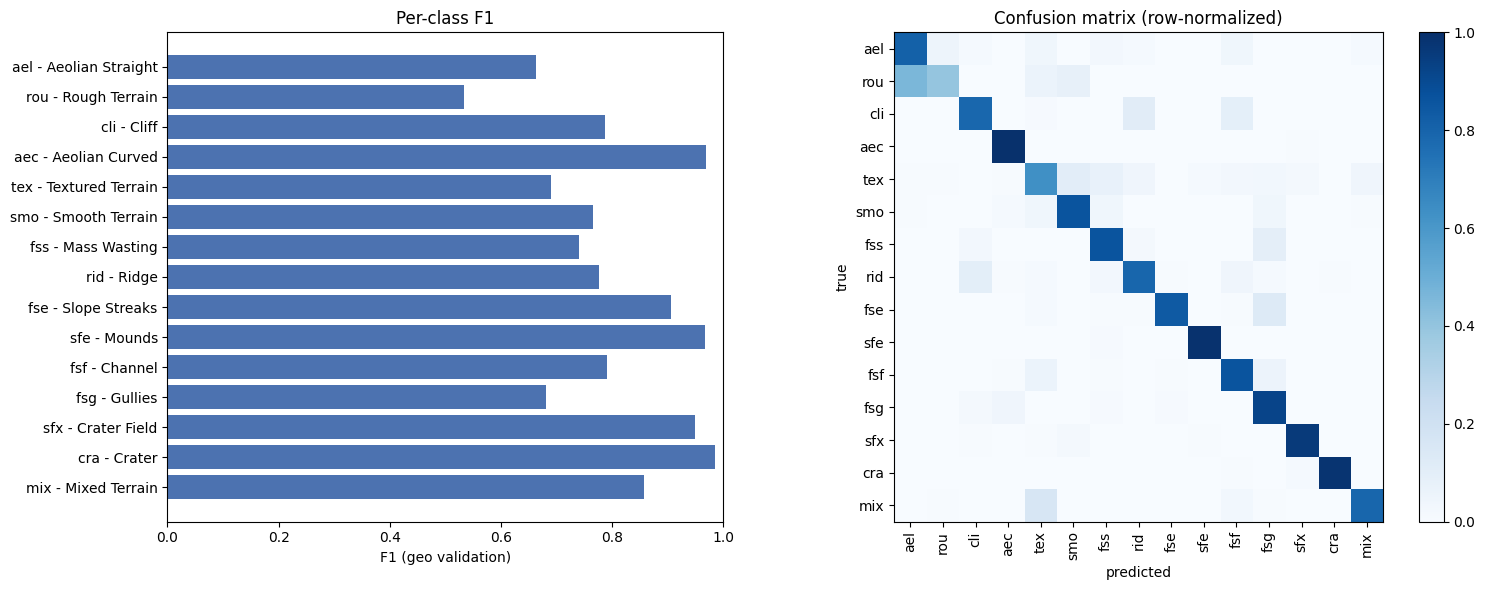

In [30]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

val_pred = mars_cls.predict_proba(clf, X_val).argmax(1)
val_scores = mars_cls.scores(y_val, val_pred)
names = [f'{ID2CODE[i]} - {ID2NAME[i]}' for i in range(15)]
val_table = pd.DataFrame({'class': names, 'val F1': val_scores['per_class_f1'],
                          'val precision': val_scores['per_class_precision'],
                          'val images': np.bincount(y_val, minlength=15)})
val_table.to_csv(RESULTS_DIR / 'phase2_val_per_class.csv', index=False)
print(f"Validation accuracy {val_scores['acc']:.3f} | macro-F1 {val_scores['macro_f1']:.3f}")
display(val_table)

fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.3]})
ax[0].barh(names[::-1], val_scores['per_class_f1'][::-1], color='#4C72B0')
ax[0].set_xlim(0, 1); ax[0].set_xlabel('F1 (geo validation)'); ax[0].set_title('Per-class F1')
cm = confusion_matrix(y_val, val_pred, labels=range(15), normalize='true')
im = ax[1].imshow(cm, cmap='Blues', vmin=0, vmax=1)
codes = [ID2CODE[i] for i in range(15)]
ax[1].set_xticks(range(15), codes, rotation=90); ax[1].set_yticks(range(15), codes)
ax[1].set_xlabel('predicted'); ax[1].set_ylabel('true'); ax[1].set_title('Confusion matrix (row-normalized)')
plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'phase2_val_f1_confusion.png', dpi=120, bbox_inches='tight'); plt.show()

### Cell 19 — Notes, config, and GitHub commit for Phase 2
Adds the Phase 2 section to PROJECT_NOTES.md, saves the run settings, and pushes one commit to GitHub.

In [31]:
from google.colab import userdata
write_note('phase2', f"""
## Phase 2 - Baseline classifier (real only)
- Model: {CLS_CFG['arch']} (ImageNet-22k pretrained), 15 classes, input 200 px grayscale -> 224 px, 3 channels.
- Training: {CLS_CFG['steps']} steps, batch {CLS_CFG['bs']}, AdamW lr {CLS_CFG['lr']}, wd {CLS_CFG['wd']}, cosine schedule, label smoothing {CLS_CFG['label_smoothing']}, fp16. Augment: {CLS_CFG['augment']}.
- Selected on geo VAL macro-F1 (best step {base_info['best_step']}); training time {base_info.get('seconds', '?')} s on a T4.
- **Geo-val accuracy {val_scores['acc']:.3f}, macro-F1 {val_scores['macro_f1']:.3f}.** Test set not used (scored once in Phase 6).

{md_table(val_table)}

- This model is the Phase 4 filter; its per-class precision above tells how much to trust the filter for each class.
""")
mars_utils.save_run_config({**CLS_CFG, 'phase': 2, 'val': {k: val_scores[k] for k in ['acc', 'macro_f1']},
                            'best_step': base_info['best_step']}, CONFIG_DIR, 'phase2_baseline')
mars_utils.mark_phase_done(ROOT, 'phase2')
token = userdata.get('GITHUB_TOKEN')
github_sync.sync(ROOT, f"Phase 2: ConvNeXt-Tiny real-only baseline (geo-val macro-F1 {val_scores['macro_f1']:.3f})", token)
del token

Saved run config -> /content/drive/MyDrive/mars_data_engine/run_configs/phase2_baseline.json
Pushed: Phase 2: ConvNeXt-Tiny real-only baseline (geo-val macro-F1 0.804)  (17 files)  ->  https://github.com/guptuv/Mars-Terrain-Diffusion


# Phase 3 — LoRA fine-tuning of Stable Diffusion 1.5
**LoRA** adds small trainable matrices to the attention layers of the frozen Stable Diffusion UNet. Only about 3 M of its 860 M weights are trained, which fits a T4. We train on **real geo-train CTX tiles** (up to 400 per class, all 15 classes), each with a class caption such as *"CTX orbital image of Mars, crater, a single impact crater with a raised rim and bowl-shaped floor, grayscale"*. 10% of captions are dropped, so the model also learns the unconditional mode that classifier-free guidance needs. (The old project used guidance scale 0, which turns guidance off, so prompts were ignored.)

### Cell 20 — Captions and latent cache
Upscales each 200 px tile to 512 px and encodes it once with the SD VAE into a 64×64 "latent". The latents are cached on Drive, so training never runs the VAE again and can resume after a disconnect. The captions are also encoded once with the CLIP text encoder.

In [32]:
import gc, time, torch, numpy as np, torch.nn.functional as F
from diffusers import AutoencoderKL
from transformers import CLIPTextModel, CLIPTokenizer

SD = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
LORA_DIR = ROOT / 'checkpoints/lora'
DETAIL = {
    'ael': 'straight parallel wind-blown ripples and dune ridges',
    'aec': 'curved crescent-shaped dunes with sinuous crests',
    'cli': 'a steep cliff scarp with a sharp edge and shadowed face',
    'rid': 'a long narrow raised ridge',
    'fsf': 'a winding channel carved into the surface',
    'sfe': 'rounded mounds rising from the plain',
    'fsg': 'gullies with alcoves and channels on a slope',
    'fse': 'dark and bright streaks running down a slope',
    'fss': 'mass-wasting deposits and slumped debris on a slope',
    'cra': 'a single impact crater with a raised rim and bowl-shaped floor',
    'sfx': 'a field of many small impact craters',
    'mix': 'mixed terrain with several landforms',
    'rou': 'rough, rocky, hummocky terrain',
    'smo': 'smooth, flat, nearly featureless plains',
    'tex': 'textured terrain with a fine repeating surface pattern'}

def caption(code):
    return f'CTX orbital image of Mars, {ID2NAME[CODE2ID[code]].lower()}, {DETAIL[code]}, grayscale'

LORA_CFG = {'base_model': SD, 'resolution': 512, 'rank': 16, 'alpha': 16,
            'target_modules': ['to_q', 'to_k', 'to_v', 'to_out.0'], 'lr': 1e-4, 'optimizer': 'AdamW8bit',
            'steps': 1000, 'batch': 4, 'grad_clip': 1.0, 'caption_dropout': 0.1, 'per_class_cap': 400,
            'mixed_precision': 'fp16', 'gradient_checkpointing': True, 'seed': 42, 'save_every': 250,
            'captions': {c: caption(c) for c in DETAIL}}

lat_path = LORA_DIR / 'latents_cache.pt'
if lat_path.exists():
    cache = torch.load(lat_path)
    print('Loaded cached latents:', tuple(cache['latents'].shape))
else:
    rng = np.random.default_rng(42)
    pick = np.sort(np.concatenate([rng.choice(np.where(y_train == c)[0], min(400, (y_train == c).sum()), replace=False)
                                   for c in range(15)]))
    vae = AutoencoderKL.from_pretrained(SD, subfolder='vae', torch_dtype=torch.float16).cuda().eval()
    lats, g, t0 = [], torch.Generator('cuda').manual_seed(42), time.time()
    with torch.no_grad():
        for k in range(0, len(pick), 16):
            x = torch.from_numpy(X_train[pick[k:k + 16]]).cuda().float().div(255).unsqueeze(1)
            x = F.interpolate(x, size=512, mode='bicubic', align_corners=False).clamp(0, 1)   # 200 px -> 512 px
            x = (x.expand(-1, 3, -1, -1) * 2 - 1).half()                                        # gray -> RGB, range [-1, 1]
            lats.append((vae.encode(x).latent_dist.sample(generator=g) * vae.config.scaling_factor).cpu())
            if k % 800 == 0: print(f'  encoded {k}/{len(pick)}  ({time.time() - t0:.0f}s)')
    cache = {'latents': torch.cat(lats), 'labels': torch.from_numpy(y_train[pick]), 'train_index': torch.from_numpy(pick)}
    torch.save(cache, lat_path)
    del vae; gc.collect(); torch.cuda.empty_cache()
    print('Saved latents:', tuple(cache['latents'].shape), f'in {time.time() - t0:.0f}s')

# Encode the 15 captions + 1 empty caption (index 15 = "no caption", used for caption dropout)
tok = CLIPTokenizer.from_pretrained(SD, subfolder='tokenizer')
te = CLIPTextModel.from_pretrained(SD, subfolder='text_encoder').cuda().half().eval()
caps = [caption(ID2CODE[c]) for c in range(15)] + ['']
with torch.no_grad():
    ids = tok(caps, padding='max_length', max_length=tok.model_max_length, truncation=True, return_tensors='pt').input_ids.cuda()
    text_emb = te(ids)[0].cpu()
del te; gc.collect(); torch.cuda.empty_cache()
print('Caption embeddings:', tuple(text_emb.shape))
print('Example caption:', caps[CODE2ID['cra']])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

  encoded 0/6000  (10s)
  encoded 800/6000  (91s)
  encoded 1600/6000  (172s)
  encoded 2400/6000  (252s)
  encoded 3200/6000  (332s)
  encoded 4000/6000  (412s)
  encoded 4800/6000  (492s)
  encoded 5600/6000  (571s)
Saved latents: (6000, 4, 64, 64) in 611s


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

... (4 outputs left out)

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Caption embeddings: (16, 77, 768)
Example caption: CTX orbital image of Mars, crater, a single impact crater with a raised rim and bowl-shaped floor, grayscale


### Cell 21 — Train the LoRA (about 25–35 minutes on a T4)
Each step takes 4 cached latents, adds random noise at a random strength, and teaches the UNet (through the LoRA weights only) to predict that noise from the caption. Progress is saved to Drive every 250 steps, so if Colab disconnects you can **just re-run this cell** and it continues from the last save.

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


Trainable LoRA parameters: 3.19 M


scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

step 50/1000  loss(avg 50) 0.1886  1.27s/step  ~20 min left
step 100/1000  loss(avg 50) 0.2099  1.21s/step  ~18 min left
step 150/1000  loss(avg 50) 0.1697  1.19s/step  ~17 min left
step 200/1000  loss(avg 50) 0.1845  1.19s/step  ~16 min left
step 250/1000  loss(avg 50) 0.1883  1.18s/step  ~15 min left
  checkpoint saved at step 250
step 300/1000  loss(avg 50) 0.1954  1.18s/step  ~14 min left
step 350/1000  loss(avg 50) 0.1761  1.18s/step  ~13 min left
step 400/1000  loss(avg 50) 0.1991  1.17s/step  ~12 min left
step 450/1000  loss(avg 50) 0.2268  1.17s/step  ~11 min left
step 500/1000  loss(avg 50) 0.1595  1.17s/step  ~10 min left
  checkpoint saved at step 500
step 550/1000  loss(avg 50) 0.1722  1.17s/step  ~9 min left
step 600/1000  loss(avg 50) 0.1689  1.17s/step  ~8 min left
step 650/1000  loss(avg 50) 0.1812  1.17s/step  ~7 min left
step 700/1000  loss(avg 50) 0.1787  1.17s/step  ~6 min left
step 750/1000  loss(avg 50) 0.2093  1.17s/step  ~5 min left
  checkpoint saved at step 75

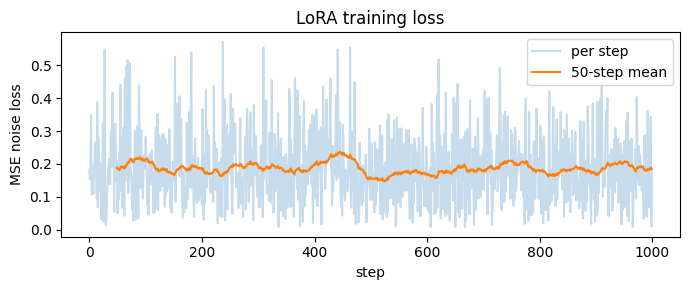

In [33]:
import bitsandbytes as bnb, os
from diffusers import UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict

final_dir = LORA_DIR / 'final'
if (final_dir / 'pytorch_lora_weights.safetensors').exists():
    print('LoRA already trained - skipping. (Delete checkpoints/lora/final to retrain.)')
else:
    mars_utils.set_seed(LORA_CFG['seed']); torch.backends.cudnn.benchmark = True
    unet = UNet2DConditionModel.from_pretrained(SD, subfolder='unet', torch_dtype=torch.float16).cuda()
    unet.requires_grad_(False)
    unet.enable_gradient_checkpointing()            # trades compute for memory, needed on a T4
    unet.add_adapter(LoraConfig(r=LORA_CFG['rank'], lora_alpha=LORA_CFG['alpha'], init_lora_weights='gaussian',
                                target_modules=LORA_CFG['target_modules']))
    lora_params = [p for p in unet.parameters() if p.requires_grad]
    for p in lora_params: p.data = p.data.float()  # LoRA weights in fp32, frozen UNet in fp16
    print(f'Trainable LoRA parameters: {sum(p.numel() for p in lora_params) / 1e6:.2f} M')

    opt = bnb.optim.AdamW8bit(lora_params, lr=LORA_CFG['lr'], weight_decay=1e-2)
    scaler = torch.amp.GradScaler('cuda')
    noise_sched = DDPMScheduler.from_pretrained(SD, subfolder='scheduler')
    state_path = LORA_DIR / 'train_state.pt'
    start, losses = 0, []
    if state_path.exists():                          # resume after a disconnect
        st = torch.load(state_path, weights_only=False)
        set_peft_model_state_dict(unet, st['lora']); opt.load_state_dict(st['opt']); scaler.load_state_dict(st['scaler'])
        start, losses = st['step'], st['losses']
        print('Resuming from step', start)

    lat, lab, N, B = cache['latents'], cache['labels'], len(cache['latents']), LORA_CFG['batch']
    g = torch.Generator().manual_seed(LORA_CFG['seed'] + start)
    unet.train(); t0 = time.time()
    for step in range(start + 1, LORA_CFG['steps'] + 1):
        idx = torch.randint(0, N, (B,), generator=g)
        x0 = lat[idx].cuda().float()
        noise = torch.randn_like(x0)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (B,), device='cuda')
        xt = noise_sched.add_noise(x0, noise, t)
        cond = lab[idx].clone()
        cond[torch.rand(B, generator=g) < LORA_CFG['caption_dropout']] = 15       # 15 = empty caption
        with torch.autocast('cuda', dtype=torch.float16):
            pred = unet(xt.half(), t, text_emb[cond].cuda()).sample
        loss = F.mse_loss(pred.float(), noise)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(lora_params, LORA_CFG['grad_clip'])
        scaler.step(opt); scaler.update()
        losses.append(round(loss.item(), 5))
        if step % 50 == 0:
            rate = (time.time() - t0) / (step - start)
            print(f'step {step}/{LORA_CFG["steps"]}  loss(avg 50) {np.mean(losses[-50:]):.4f}  '
                  f'{rate:.2f}s/step  ~{rate * (LORA_CFG["steps"] - step) / 60:.0f} min left')
        if step % LORA_CFG['save_every'] == 0 or step == LORA_CFG['steps']:
            tmp = LORA_DIR / 'train_state.tmp'
            torch.save({'lora': get_peft_model_state_dict(unet), 'opt': opt.state_dict(),
                        'scaler': scaler.state_dict(), 'step': step, 'losses': losses}, tmp)
            os.replace(tmp, state_path)              # atomic: a disconnect never leaves a half-written file
            print('  checkpoint saved at step', step)

    StableDiffusionPipeline.save_lora_weights(save_directory=str(final_dir), safe_serialization=True,
        unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
    json.dump(losses, open(LORA_DIR / 'losses.json', 'w'))
    print('Saved final LoRA ->', final_dir)
    del unet, opt; gc.collect(); torch.cuda.empty_cache()

losses = json.load(open(LORA_DIR / 'losses.json'))
sm = np.convolve(losses, np.ones(50) / 50, mode='valid')
plt.figure(figsize=(7, 3)); plt.plot(losses, alpha=0.25, label='per step'); plt.plot(range(49, len(losses)), sm, label='50-step mean')
plt.xlabel('step'); plt.ylabel('MSE noise loss'); plt.title('LoRA training loss'); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'phase3_lora_loss.png', dpi=120); plt.show()

### Cell 22 — Preview: real vs generated, and the effect of guidance scale
Loads SD 1.5 with the trained LoRA and generates 4 images per target class (guidance 6.5, 4 different seeds), shown next to 4 real tiles. The second figure uses one fixed seed and changes only the guidance scale (0 → 10), which shows why the old project's guidance 0 ignored the prompt.

In [34]:
from diffusers import DPMSolverMultistepScheduler

pipe = StableDiffusionPipeline.from_pretrained(SD, torch_dtype=torch.float16, safety_checker=None,
                                               requires_safety_checker=False).to('cuda')
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe.load_lora_weights(str(LORA_DIR / 'final'))

TARGET = ['cra', 'cli', 'rid', 'ael', 'aec', 'rou', 'smo']   # DoMars codes that map to my classes
def generate(prompt, seeds, guidance, steps=25):
    gens = [torch.Generator('cuda').manual_seed(int(s)) for s in seeds]
    return [im.convert('L') for im in pipe([prompt] * len(seeds), num_inference_steps=steps,
                                            guidance_scale=guidance, generator=gens).images]

rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(TARGET), 8, figsize=(16, 2.1 * len(TARGET)))
for r, code in enumerate(TARGET):
    real_idx = rng.choice(np.where(y_train == CODE2ID[code])[0], 4, replace=False)
    fakes = generate(caption(code), seeds=[1, 2, 3, 4], guidance=6.5)
    for c in range(8):
        ax = axes[r, c]; ax.axis('off')
        ax.imshow(X_train[real_idx[c]] if c < 4 else fakes[c - 4], cmap='gray')
        if r == 0: ax.set_title('REAL' if c < 4 else 'GENERATED (LoRA)', fontsize=9)
    axes[r, 0].text(-20, 100, f'{code}\n{ID2NAME[CODE2ID[code]]}', ha='right', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'phase3_preview_real_vs_generated.png', dpi=110, bbox_inches='tight'); plt.show()

sweep = [0, 3, 6.5, 10]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, gs in zip(axes, sweep):
    ax.imshow(generate(caption('cra'), [7], gs)[0], cmap='gray'); ax.axis('off'); ax.set_title(f'guidance {gs}')
plt.suptitle('Same seed, prompt "crater" - only the guidance scale changes'); plt.tight_layout()
plt.savefig(RESULTS_DIR / 'phase3_guidance_sweep.png', dpi=110, bbox_inches='tight'); plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Cell 23 — Notes, config, and GitHub commit for Phase 3
Records the LoRA settings and final loss, and pushes the preview figures. The LoRA weights themselves (about 13 MB) stay on Drive.

In [35]:
from google.colab import userdata
write_note('phase3', f"""
## Phase 3 - LoRA fine-tuning (SD 1.5)
- Base model {SD}; LoRA rank {LORA_CFG['rank']} (alpha {LORA_CFG['alpha']}) on UNet attention ({', '.join(LORA_CFG['target_modules'])}).
- Data: {len(cache['latents'])} geo-train tiles (up to {LORA_CFG['per_class_cap']} per class, all 15 classes), 200 px upscaled to 512 px, VAE latents cached.
- {LORA_CFG['steps']} steps, batch {LORA_CFG['batch']}, AdamW8bit lr {LORA_CFG['lr']}, fp16 + gradient checkpointing, caption dropout {LORA_CFG['caption_dropout']}, seed {LORA_CFG['seed']}.
- Final loss (mean of last 100 steps): {np.mean(losses[-100:]):.4f}. Figures: results/phase3_lora_loss.png, results/phase3_preview_real_vs_generated.png, results/phase3_guidance_sweep.png.
- Preview sampler: DPM-Solver++ 25 steps, guidance 6.5. Guidance sweep 0 / 3 / 6.5 / 10 shows that guidance 0 (old project) ignores the prompt.
- Caption template: "CTX orbital image of Mars, <class>, <class detail>, grayscale".
""")
mars_utils.save_run_config({**LORA_CFG, 'phase': 3, 'n_train_latents': int(len(cache['latents'])),
                            'final_loss_last100': float(np.mean(losses[-100:]))}, CONFIG_DIR, 'phase3_lora')
mars_utils.mark_phase_done(ROOT, 'phase3')
token = userdata.get('GITHUB_TOKEN')
github_sync.sync(ROOT, f"Phase 3: LoRA (rank {LORA_CFG['rank']}, {LORA_CFG['steps']} steps) on CTX tiles, previews and guidance sweep", token)
del token

Saved run config -> /content/drive/MyDrive/mars_data_engine/run_configs/phase3_lora.json
Pushed: Phase 3: LoRA (rank 16, 1000 steps) on CTX tiles, previews and guidance sweep  (22 files)  ->  https://github.com/guptuv/Mars-Terrain-Diffusion


# Phase 4 — Generate labeled images, then filter them with the classifier
We generate images only for the DoMars16k classes that match your terrain classes: craters (cra), cliffs (cli), ridges (rid), sand dunes (ael + aec), rock fields ≈ rough terrain (rou), and volcanic plains ≈ smooth terrain (smo). We vary **seed** (unique per image), **prompt wording** (3 templates) and **guidance scale** (5, 6, 7).

### Cell 24 — Generate (about 50–60 minutes on a T4; resumable)
Images are saved to Drive as 512 px grayscale PNGs, one folder per class. If the session drops, re-run this cell: images that already exist are skipped, and the seeds are fixed, so the result is identical. A log of every image (prompt, seed, guidance) is saved as CSV.

In [36]:
import pandas as pd
GEN_RAW = ROOT / 'generated/raw'
GEN_FILT = ROOT / 'generated/filtered'
N_PER_CODE = {'cra': 150, 'cli': 150, 'rid': 150, 'ael': 75, 'aec': 75, 'rou': 150, 'smo': 150}  # dunes = 75 + 75
TEMPLATES = [lambda c: caption(c),
             lambda c: f'CTX orbital image of Mars showing {DETAIL[c]}, grayscale',
             lambda c: f'grayscale CTX orbital image of the Martian surface, {ID2NAME[CODE2ID[c]].lower()}']
GEN_CFG = {'sampler': 'DPMSolverMultistep', 'steps': 25, 'guidance_values': [5.0, 6.0, 7.0], 'batch': 4,
           'n_per_code': N_PER_CODE, 'resolution': 512, 'lora': str(LORA_DIR / 'final'),
           'seed_rule': 'seed = 100000 * class_id + image_index',
           'templates': ['CTX orbital image of Mars, <class>, <detail>, grayscale',
                         'CTX orbital image of Mars showing <detail>, grayscale',
                         'grayscale CTX orbital image of the Martian surface, <class>']}

rows, t0, made = [], time.time(), 0
for code in TARGET:
    out = GEN_RAW / code; out.mkdir(parents=True, exist_ok=True)
    n, B = N_PER_CODE[code], GEN_CFG['batch']
    for k in range(0, n, B):
        b = k // B
        ids = list(range(k, min(k + B, n)))
        prompt_id = b % 3                                   # rotate prompt wording every batch
        guidance = GEN_CFG['guidance_values'][(b // 3) % 3]  # rotate guidance every 3 batches
        prompt = TEMPLATES[prompt_id](code)
        seeds = [100000 * CODE2ID[code] + i for i in ids]
        files = [out / f'{code}_{i:04d}.png' for i in ids]
        if not all(f.exists() for f in files):
            for im, f in zip(generate(prompt, seeds, guidance, steps=GEN_CFG['steps']), files):
                im.save(f)
            made += len(ids)
        rows += [{'file': str(f), 'code': code, 'label': CODE2ID[code], 'prompt_id': prompt_id,
                  'prompt': prompt, 'seed': s, 'guidance': guidance} for f, s in zip(files, seeds)]
    rate = (time.time() - t0) / max(made, 1)
    print(f'{code}: {n} images ready  |  {made} generated this session  |  {rate:.1f} s/image')

gen_log = pd.DataFrame(rows)
gen_log.to_csv(RESULTS_DIR / 'phase4_generation_log.csv', index=False)
print('Total images:', len(gen_log), ' time:', round((time.time() - t0) / 60, 1), 'min')

cra: 150 images ready  |  150 generated this session  |  4.1 s/image
cli: 150 images ready  |  300 generated this session  |  4.0 s/image
rid: 150 images ready  |  450 generated this session  |  4.0 s/image
ael: 75 images ready  |  525 generated this session  |  4.1 s/image
aec: 75 images ready  |  600 generated this session  |  4.1 s/image
rou: 150 images ready  |  750 generated this session  |  4.0 s/image
smo: 150 images ready  |  900 generated this session  |  4.0 s/image
Total images: 900  time: 60.7 min


### Cell 25 — Filter with the Phase 2 classifier
Each generated image is shrunk to 200 px (the same size as the real tiles) and classified. We **keep** an image only if the classifier's top prediction is the intended class **and** its confidence is at least 0.6. Kept images are copied to generated/filtered/.

In [ ]:
import shutil
THRESH = 0.6
X_gen = np.stack([mars_cls.decode(f) for f in gen_log['file']])
probs = mars_cls.predict_proba(clf, X_gen)
gen_log['pred'] = probs.argmax(1)
gen_log['pred_code'] = gen_log['pred'].map(ID2CODE)
gen_log['conf_intended'] = probs[np.arange(len(probs)), gen_log['label'].values].round(4)
gen_log['kept'] = (gen_log['pred'] == gen_log['label']) & (gen_log['conf_intended'] >= THRESH)

for code in TARGET:
    (GEN_FILT / code).mkdir(parents=True, exist_ok=True)
for f, code, kept in zip(gen_log['file'], gen_log['code'], gen_log['kept']):
    dst = GEN_FILT / code / Path(f).name
    if kept and not dst.exists(): shutil.copy(f, dst)
    if not kept and dst.exists(): dst.unlink()      # keeps the folder consistent if the threshold changes
gen_log.to_csv(RESULTS_DIR / 'phase4_generation_log.csv', index=False)

MY = {'cra': 'craters', 'cli': 'cliffs', 'rid': 'ridges', 'ael': 'sand dunes', 'aec': 'sand dunes',
      'rou': 'rock fields (approx.)', 'smo': 'volcanic plains (approx.)'}
keep_table = gen_log.groupby('code').agg(generated=('kept', 'size'), kept=('kept', 'sum'),
                                         mean_conf=('conf_intended', 'mean')).reindex(TARGET)
keep_table['keep rate'] = (keep_table['kept'] / keep_table['generated']).round(3)
keep_table['mean_conf'] = keep_table['mean_conf'].round(3)
keep_table.insert(0, 'my class', [MY[c] for c in keep_table.index])
keep_table.loc['ALL'] = ['-', keep_table['generated'].sum(), keep_table['kept'].sum(),
                         round(gen_log['conf_intended'].mean(), 3), round(gen_log['kept'].mean(), 3)]
keep_table.to_csv(RESULTS_DIR / 'phase4_kept_per_class.csv')
display(keep_table)

# Most common wrong predictions: tells us what the generator confuses each class with
wrong = gen_log[gen_log['pred'] != gen_log['label']]
print('\nMost common wrong predictions (intended -> predicted):')
print(wrong.groupby(['code', 'pred_code']).size().sort_values(ascending=False).head(10).to_string())

# Keep rate by prompt wording and by guidance scale
print('\nKeep rate by prompt template:'); print(gen_log.groupby('prompt_id')['kept'].mean().round(3).to_string())
print('\nKeep rate by guidance scale:'); print(gen_log.groupby('guidance')['kept'].mean().round(3).to_string())

### Cell 26 — Look at kept vs rejected images
For each class: 4 kept images (green title) and 4 rejected images (red title, with what the classifier thought they were). Always look at the pictures, not just the numbers.

In [ ]:
fig, axes = plt.subplots(len(TARGET), 8, figsize=(16, 2.2 * len(TARGET)))
rng = np.random.default_rng(1)
for r, code in enumerate(TARGET):
    sub = gen_log[gen_log['code'] == code]
    kept = sub[sub['kept']]; rej = sub[~sub['kept']]
    picks = [(row, True) for _, row in kept.sample(min(4, len(kept)), random_state=1).iterrows()] + \
            [(row, False) for _, row in rej.sample(min(4, len(rej)), random_state=1).iterrows()]
    for c in range(8):
        ax = axes[r, c]; ax.axis('off')
        if c < len(picks):
            row, ok = picks[c]
            ax.imshow(Image.open(row['file']).convert('L'), cmap='gray')
            ax.set_title(f"kept {row['conf_intended']:.2f}" if ok else f"rejected -> {row['pred_code']}",
                         fontsize=8, color='green' if ok else 'red')
    axes[r, 0].text(-40, 256, f'{code}\n{MY[code]}', ha='right', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'phase4_kept_vs_rejected.png', dpi=100, bbox_inches='tight'); plt.show()

### Cell 27 — Notes, config, and GitHub commit for Phase 4

In [ ]:
from google.colab import userdata
GEN_CFG['filter'] = {'classifier': str(base_ckpt), 'rule': 'pred == intended and confidence >= THRESH', 'threshold': THRESH}
by_g = gen_log.groupby('guidance')['kept'].mean().round(3).to_dict()
by_p = gen_log.groupby('prompt_id')['kept'].mean().round(3).to_dict()
write_note('phase4', f"""
## Phase 4 - Generation and filtering
- {len(gen_log)} images generated with SD 1.5 + LoRA ({GEN_CFG['sampler']}, {GEN_CFG['steps']} steps, 512 px), seeds {GEN_CFG['seed_rule']}.
- Varied: 3 prompt templates, guidance scale {GEN_CFG['guidance_values']}.
- Filter: Phase 2 classifier on 200 px downsized images; keep if predicted class = intended class and confidence >= {THRESH}.
- **Kept {int(gen_log['kept'].sum())} of {len(gen_log)} ({gen_log['kept'].mean():.1%}).**

{md_table(keep_table.reset_index().rename(columns={'index': 'code'}))}

- Keep rate by guidance scale: {by_g}. By prompt template: {by_p}.
- Figure: results/phase4_kept_vs_rejected.png. Full per-image log: results/phase4_generation_log.csv.
""")
mars_utils.save_run_config({**GEN_CFG, 'phase': 4, 'n_generated': len(gen_log), 'n_kept': int(gen_log['kept'].sum()),
                            'keep_rate_by_guidance': by_g, 'keep_rate_by_prompt': by_p}, CONFIG_DIR, 'phase4_generation')
mars_utils.mark_phase_done(ROOT, 'phase4')
token = userdata.get('GITHUB_TOKEN')
github_sync.sync(ROOT, f"Phase 4: generated {len(gen_log)} images, kept {int(gen_log['kept'].sum())} after classifier filtering", token)
del token

# Phase 5 — Set-level evaluation
Pairwise scores (SSIM, LPIPS, …) compare one image with one other image. They can't tell whether a **set** of images is realistic and varied. Here we compare whole sets against the **real geo-test tiles** of the same class. (This uses test images only as a reference set: nothing is trained or tuned on them.)

| Metric | Question it answers | Better |
|---|---|---|
| **FID** (Inception) | Do the two sets have the same feature statistics? | lower |
| **KID** (Inception) | Same question, but less biased for small sets (≈100–300 images) | lower |
| **FD-DINOv2** | FID in DINOv2 feature space, which tracks human judgement better | lower |
| **Precision** (DINOv2, k=3) | Realism: what share of generated images fall inside the real data manifold | higher |
| **Recall** (DINOv2, k=3) | Coverage: what share of real images are "covered" by generated ones | higher |
| **Vendi score** (DINOv2 / CLIP) | Diversity: the effective number of distinct images in a set | higher |

To make the numbers readable, every metric is also computed for **real geo-train vs real geo-test** (same size). That is the "real vs real" floor, the best a perfect generator could hope for.

### Cell 28 — Feature extractors and metric functions
Loads three frozen feature networks (Inception-v3, DINOv2 ViT-S/14, CLIP ViT-B/32) and defines the metrics. Every image is used at the same 200 px grayscale size as the real tiles.

In [ ]:
import timm, open_clip
from scipy import linalg
from torchmetrics.image.fid import FrechetInceptionDistance

inception = FrechetInceptionDistance(feature=2048).inception.cuda().eval()   # standard FID Inception-v3
dino = timm.create_model('vit_small_patch14_dinov2.lvd142m', pretrained=True, num_classes=0, img_size=224).cuda().eval()
clip_model, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
clip_model = clip_model.cuda().eval()
CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073]).view(1, 3, 1, 1).cuda()
CLIP_STD = torch.tensor([0.26862954, 0.26130258, 0.27577711]).view(1, 3, 1, 1).cuda()
IMNET_MEAN, IMNET_STD = mars_cls.MEAN.cuda(), mars_cls.STD.cuda()

@torch.no_grad()
def features(X, bs=128):
    """uint8 [N,200,200] -> dict of feature matrices (numpy float64)."""
    out = {'inception': [], 'dino': [], 'clip': []}
    for k in range(0, len(X), bs):
        x8 = torch.from_numpy(X[k:k + bs]).cuda().unsqueeze(1).expand(-1, 3, -1, -1).contiguous()
        out['inception'].append(inception(x8).double().cpu())        # FID Inception resizes to 299 itself
        x = F.interpolate(x8.float() / 255, size=224, mode='bilinear', antialias=True, align_corners=False)
        with torch.autocast('cuda', dtype=torch.float16):
            out['dino'].append(F.normalize(dino((x - IMNET_MEAN) / IMNET_STD).float(), dim=1).double().cpu())
            out['clip'].append(F.normalize(clip_model.encode_image((x - CLIP_MEAN) / CLIP_STD).float(), dim=1).double().cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}

def frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))

def kid(a, b, n_subsets=50, seed=0):
    """Unbiased MMD^2 with a cubic polynomial kernel (Binkowski et al., 2018). Returns (mean, std)."""
    rng, d = np.random.default_rng(seed), a.shape[1]
    m = min(100, len(a), len(b)); vals = []
    for _ in range(n_subsets):
        x, y = a[rng.choice(len(a), m, replace=False)], b[rng.choice(len(b), m, replace=False)]
        kxx, kyy, kxy = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))

def precision_recall(real, fake, k=3):
    """Kynkaanniemi et al., 2019: k-NN manifold estimate in feature space."""
    r, f = torch.from_numpy(real).float().cuda(), torch.from_numpy(fake).float().cuda()
    rad_r = torch.cdist(r, r).kthvalue(k + 1, dim=1).values       # k+1 because the nearest point is itself
    rad_f = torch.cdist(f, f).kthvalue(k + 1, dim=1).values
    d = torch.cdist(f, r)                                          # [n_fake, n_real]
    precision = (d <= rad_r[None, :]).any(1).float().mean().item()
    recall = (d.T <= rad_f[None, :]).any(1).float().mean().item()
    return precision, recall

def vendi(feat):
    """Vendi score (Friedman & Dieng, 2023) with cosine similarity: exp(entropy of the kernel's eigenvalues)."""
    K = feat @ feat.T / len(feat)
    ev = np.clip(np.linalg.eigvalsh(K), 0, None); ev = ev[ev > 1e-12]
    return float(np.exp(-(ev * np.log(ev)).sum()))

def compare(real_f, fake_f):
    p, r = precision_recall(real_f['dino'], fake_f['dino'])
    k_mean, k_std = kid(real_f['inception'], fake_f['inception'])
    return {'FID': frechet(real_f['inception'], fake_f['inception']), 'KID': k_mean, 'KID_std': k_std,
            'FD_DINOv2': frechet(real_f['dino'], fake_f['dino']), 'precision': p, 'recall': r,
            'Vendi_DINOv2': vendi(fake_f['dino']), 'Vendi_CLIP': vendi(fake_f['clip']), 'n': len(fake_f['dino'])}
print('Feature extractors ready.')

### Cell 29 — Compute all metrics per class and overall
For each target class we compare four sets against real geo-test: **real geo-train** (the reference floor), **all generated** images, **filtered** generated images, and (if uploaded to old_project_images/) your **old project's** images. Results go to results/phase5_metrics.csv.

In [ ]:
geo_te, X_te = mars_cls.load_geo(DATA_DIR, SPLITS_DIR, which=('test',))
y_te = geo_te['label'].values
gen_log = pd.read_csv(RESULTS_DIR / 'phase4_generation_log.csv')
X_gen = np.stack([mars_cls.decode(f) for f in gen_log['file']])

rows = []
def add_rows(group, real_X, sets):
    real_f = features(real_X)
    rows.append({'group': group, 'set': 'real test (itself)', **{'Vendi_DINOv2': vendi(real_f['dino']),
                 'Vendi_CLIP': vendi(real_f['clip']), 'n': len(real_X)}})
    for name, X in sets.items():
        if len(X) >= 10:
            rows.append({'group': group, 'set': name, **compare(real_f, features(X))})

rng = np.random.default_rng(0)
groups = {c: [c] for c in TARGET}
groups['ALL target classes'] = TARGET
for group, codes in groups.items():
    ids = [CODE2ID[c] for c in codes]
    real_X = X_te[np.isin(y_te, ids)]
    tr_pool = np.where(np.isin(y_train, ids))[0]
    ref = X_train[rng.choice(tr_pool, min(len(real_X), len(tr_pool)), replace=False)]   # same size as real test
    m_all = gen_log['code'].isin(codes).values
    m_kept = m_all & gen_log['kept'].values
    add_rows(group, real_X, {'real train (reference)': ref, 'generated (all)': X_gen[m_all],
                             'generated (filtered)': X_gen[m_kept]})
    print(f'{group}: real test {len(real_X)}, generated {m_all.sum()}, kept {m_kept.sum()}')

# Optional: images from the old prompt-only SD v1.4 project (no labels -> compared to all target classes)
old_files = sorted([p for p in (ROOT / 'old_project_images').rglob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg'}])
if old_files:
    X_old = np.stack([mars_cls.decode(p) for p in old_files])
    real_all = X_te[np.isin(y_te, [CODE2ID[c] for c in TARGET])]
    rows.append({'group': 'ALL target classes', 'set': 'OLD project (SD v1.4, prompt only)', **compare(features(real_all), features(X_old))})
    print('Old project images:', len(X_old))
else:
    print('No old-project images found in old_project_images/ - upload them there and re-run this cell to compare.')

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS_DIR / 'phase5_metrics.csv', index=False)
show = metrics.copy()
for c in ['FID', 'FD_DINOv2', 'Vendi_DINOv2', 'Vendi_CLIP']: show[c] = show[c].round(2)
for c in ['KID', 'KID_std', 'precision', 'recall']: show[c] = show[c].round(4)
display(show)

### Cell 30 — Plots
One panel per metric. Grey = real-vs-real reference, orange = all generated, blue = filtered. Bars closer to grey mean more realistic, for FID/KID/FD (lower), precision/recall (higher), and Vendi (closer to the real test set's own diversity, dashed line).

In [ ]:
panels = [('FID', 'FID (Inception) - lower is better'), ('KID', 'KID (Inception) - lower is better'),
          ('FD_DINOv2', 'FD-DINOv2 - lower is better'), ('precision', 'Precision (realism) - higher is better'),
          ('recall', 'Recall (coverage) - higher is better'), ('Vendi_DINOv2', 'Vendi (DINOv2) - diversity')]
order = list(groups)
sets = [('real train (reference)', '#9E9E9E'), ('generated (all)', '#DD8452'), ('generated (filtered)', '#4C72B0')]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (m, title) in zip(axes.ravel(), panels):
    for j, (s, col) in enumerate(sets):
        vals = [metrics[(metrics['group'] == g) & (metrics['set'] == s)][m].mean() for g in order]
        ax.bar(np.arange(len(order)) + (j - 1) * 0.27, vals, width=0.27, color=col, label=s)
    if m == 'Vendi_DINOv2':
        realv = [metrics[(metrics['group'] == g) & (metrics['set'] == 'real test (itself)')][m].mean() for g in order]
        ax.scatter(np.arange(len(order)), realv, marker='_', s=600, color='black', label='real test (itself)', zorder=3)
    ax.set_xticks(range(len(order)), [o if len(o) < 6 else 'ALL' for o in order]); ax.set_title(title, fontsize=11)
axes[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'phase5_metrics.png', dpi=110, bbox_inches='tight'); plt.show()

### Cell 31 — Notes, config, and GitHub commit for Phase 5

In [ ]:
from google.colab import userdata
overall = show[show['group'] == 'ALL target classes'].drop(columns=['group']).reset_index(drop=True)
write_note('phase5', f"""
## Phase 5 - Set-level evaluation (reference = real geo-test tiles of the same classes)
- Metrics: FID and KID (Inception-v3), FD-DINOv2, precision/recall (DINOv2, k=3), Vendi score (DINOv2 and CLIP, cosine kernel).
- All images compared at 200 px grayscale. "real train (reference)" = random real geo-train tiles, same size as the test set: the real-vs-real floor.
- KID is the most reliable distance here; per-class FID with only 75-300 images is biased upward.

### Overall (all target classes pooled)
{md_table(overall)}

### Per class
{md_table(show[show['group'] != 'ALL target classes'].reset_index(drop=True))}

- Figure: results/phase5_metrics.png. Old-project images: {'included' if old_files else 'not uploaded yet (put them in old_project_images/ and re-run Cell 29)'}.
""")
mars_utils.save_run_config({'phase': 5, 'reference_set': 'geo test, target classes', 'feature_nets':
                            ['inception-v3 (torchmetrics FID)', 'vit_small_patch14_dinov2.lvd142m', 'open_clip ViT-B-32 laion2b_s34b_b79k'],
                            'pr_k': 3, 'kid_subsets': 50, 'kid_subset_size': '<=100', 'image_size': 200},
                           CONFIG_DIR, 'phase5_metrics')
mars_utils.mark_phase_done(ROOT, 'phase5')
del inception, dino, clip_model; gc.collect(); torch.cuda.empty_cache()
token = userdata.get('GITHUB_TOKEN')
github_sync.sync(ROOT, 'Phase 5: set-level metrics (FID, KID, FD-DINOv2, precision/recall, Vendi) vs real geo-test', token)
del token

# Phase 6 — Downstream test: does synthetic data help? (the most important phase)
Same classifier, same recipe (1,200 steps, batch 64, the same augmentations, selected on geo-val), same seeds, **only the training data changes**:

| Condition | Real training data | Synthetic (filtered) |
|---|---|---|
| **R100** | all geo-train (≈10.9k) | – |
| **R100+S** | all geo-train | + all kept images |
| **R10** | 10% of geo-train, stratified (≈1.1k) | – |
| **R10+S** | the same 10% | + all kept images |

3 seeds per condition (0, 1, 2). With and without synthetic use the **same real subset** for a given seed (a paired comparison). Every run is scored **once** on the untouched real geo-test set. We report accuracy, macro-F1, and F1 split into the 7 classes that got synthetic images vs the 8 that did not, which catches cases where synthetic data hurts the other classes.

### Cell 32 — Verify the test lock, load the test set and the synthetic images
Re-computes the fingerprint of the geo-test IDs and stops if it differs from Phase 1.

In [ ]:
import hashlib
lock = json.load(open(SPLITS_DIR / 'test_lock.json'))
geo_all = pd.read_csv(SPLITS_DIR / 'geo_split.csv')
ids_now = '\n'.join(sorted(geo_all.loc[geo_all['geo_split'] == 'test', 'file_id']))
assert hashlib.sha256(ids_now.encode()).hexdigest() == lock['geo_split']['test_ids_sha256'], 'TEST SET CHANGED!'
print('Test-set fingerprint matches Phase 1.')

if 'X_te' not in globals():
    geo_te, X_te = mars_cls.load_geo(DATA_DIR, SPLITS_DIR, which=('test',)); y_te = geo_te['label'].values
gen_log = pd.read_csv(RESULTS_DIR / 'phase4_generation_log.csv')
kept = gen_log[gen_log['kept']]
X_syn = np.stack([mars_cls.decode(f) for f in kept['file']]); y_syn = kept['label'].values
SYN_CLASSES = sorted(set(y_syn))
print(f'test {X_te.shape}, synthetic kept {X_syn.shape}, classes with synthetic: {[ID2CODE[c] for c in SYN_CLASSES]}')

### Cell 33 — Run all 12 trainings (about 6 minutes each, ~75 minutes total; resumable)
Each finished run saves a small JSON to results/phase6_runs/. If Colab disconnects, re-run Phases 0–2 setup cells, then this cell: finished runs are skipped.

In [ ]:
RUN_DIR = RESULTS_DIR / 'phase6_runs'; RUN_DIR.mkdir(exist_ok=True)
SEEDS, FRACTIONS = [0, 1, 2], [1.0, 0.1]
train_args = {k: CLS_CFG[k] for k in ['steps', 'bs', 'lr', 'wd', 'warmup', 'eval_every', 'label_smoothing']}

def real_subset(frac, seed):
    """Stratified random subset of geo-train (identical for the with/without-synthetic pair)."""
    if frac >= 1: return np.arange(len(y_train))
    rng = np.random.default_rng(1000 + seed)
    return np.sort(np.concatenate([rng.choice(np.where(y_train == c)[0], max(1, int(round(frac * (y_train == c).sum()))), replace=False)
                                   for c in range(15)]))

for frac in FRACTIONS:
    for seed in SEEDS:
        for use_syn in [False, True]:
            name = f"R{int(frac * 100)}{'+S' if use_syn else ''}_seed{seed}"
            out = RUN_DIR / f'{name}.json'
            if out.exists():
                print('done already:', name); continue
            idx = real_subset(frac, seed)
            Xtr, ytr = X_train[idx], y_train[idx]
            if use_syn:
                Xtr, ytr = np.concatenate([Xtr, X_syn]), np.concatenate([ytr, y_syn])
            print(f'== {name}: {len(idx)} real + {len(Xtr) - len(idx)} synthetic')
            model, info = mars_cls.train_classifier(Xtr, ytr, X_val, y_val, seed=seed, **train_args)
            pred = mars_cls.predict_proba(model, X_te).argmax(1)
            res = {'name': name, 'frac_real': frac, 'synthetic': use_syn, 'seed': seed, 'n_real': int(len(idx)),
                   'n_synthetic': int(len(Xtr) - len(idx)), 'train': info, 'test': mars_cls.scores(y_te, pred)}
            json.dump(res, open(out, 'w'), indent=1)
            print(f"   test acc {res['test']['acc']:.3f}  macro-F1 {res['test']['macro_f1']:.3f}")
            del model; torch.cuda.empty_cache()

### Cell 34 — Results table (mean ± std over 3 seeds) and paired differences
"syn classes" = the 7 classes that received synthetic images; "other classes" = the remaining 8. The **paired Δ** compares each seed's +S run against its own real-only twin, which removes most seed-to-seed noise.

In [ ]:
runs = [json.load(open(p)) for p in sorted(RUN_DIR.glob('*.json'))]
OTHER = [c for c in range(15) if c not in SYN_CLASSES]
recs = []
for r in runs:
    f1 = np.array(r['test']['per_class_f1'])
    recs.append({'condition': f"R{int(r['frac_real'] * 100)}{'+S' if r['synthetic'] else ''}", 'seed': r['seed'],
                 'acc': r['test']['acc'], 'macro_f1': r['test']['macro_f1'],
                 'f1_syn_classes': f1[SYN_CLASSES].mean(), 'f1_other_classes': f1[OTHER].mean(),
                 **{f'f1_{ID2CODE[c]}': f1[c] for c in range(15)}})
runs_df = pd.DataFrame(recs)
runs_df.to_csv(RESULTS_DIR / 'phase6_all_runs.csv', index=False)

cols = ['acc', 'macro_f1', 'f1_syn_classes', 'f1_other_classes']
cond_order = ['R100', 'R100+S', 'R10', 'R10+S']
summary = runs_df.groupby('condition')[cols].agg(['mean', 'std']).reindex(cond_order)
fmt = pd.DataFrame({c: [f"{m:.3f} ± {s:.3f}" for m, s in zip(summary[(c, 'mean')], summary[(c, 'std')])] for c in cols},
                   index=cond_order)
fmt.insert(0, 'runs', runs_df.groupby('condition').size().reindex(cond_order).values)
fmt.to_csv(RESULTS_DIR / 'phase6_summary.csv')
display(fmt)

# Paired differences (+S minus real-only, same seed and same real subset)
paired = []
for base in ['R100', 'R10']:
    a = runs_df[runs_df['condition'] == base].set_index('seed')
    b = runs_df[runs_df['condition'] == base + '+S'].set_index('seed')
    d = (b[cols] - a[cols]).dropna()
    paired.append({'comparison': f'{base}+S vs {base}', 'n_pairs': len(d),
                   **{f'delta_{c}': f"{d[c].mean():+.3f} ± {d[c].std():.3f}" for c in cols},
                   '_mean_f1': d['macro_f1'].mean(), '_std_f1': d['macro_f1'].std(),
                   '_mean_syn': d['f1_syn_classes'].mean(), '_std_syn': d['f1_syn_classes'].std()})
paired_df = pd.DataFrame(paired)
display(paired_df.drop(columns=[c for c in paired_df.columns if c.startswith('_')]))

def verdict(mean, std, n):
    """Simple rule for 3 paired seeds: the effect must exceed 2 standard errors and 0.005 F1 to count."""
    se = std / np.sqrt(max(n, 1)) if n > 1 else np.inf
    if abs(mean) < 0.005 or abs(mean) < 2 * se: return 'no clear difference'
    return 'helped' if mean > 0 else 'hurt'
for _, p in paired_df.iterrows():
    print(f"{p['comparison']}: macro-F1 {verdict(p['_mean_f1'], p['_std_f1'], p['n_pairs'])}; "
          f"F1 on synthetic classes {verdict(p['_mean_syn'], p['_std_syn'], p['n_pairs'])}")

### Cell 35 — Per-class plot
Per-class test F1 for the 7 classes that got synthetic images, under all four conditions (mean over seeds; error bars = std).

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
colors = {'R100': '#9E9E9E', 'R100+S': '#4C72B0', 'R10': '#E5B88A', 'R10+S': '#DD8452'}
codes = [ID2CODE[c] for c in SYN_CLASSES]
for j, cond in enumerate(cond_order):
    sub = runs_df[runs_df['condition'] == cond]
    m = [sub[f'f1_{c}'].mean() for c in codes]; s = [sub[f'f1_{c}'].std() for c in codes]
    ax.bar(np.arange(len(codes)) + (j - 1.5) * 0.2, m, 0.2, yerr=s, capsize=2, color=colors[cond], label=cond)
ax.set_xticks(range(len(codes)), [f'{c}\n{ID2NAME[CODE2ID[c]]}' for c in codes]); ax.set_ylim(0, 1)
ax.set_ylabel('test F1 (real geo-test)'); ax.legend(ncol=4); ax.set_title('Per-class F1 on classes that received synthetic images')
plt.tight_layout(); plt.savefig(RESULTS_DIR / 'phase6_per_class_f1.png', dpi=120, bbox_inches='tight'); plt.show()

### Cell 36 — Results summary for the paper, notes, README, and final GitHub commit
Writes results/RESULTS_SUMMARY.md: what was done, the key numbers, what worked, what didn't, and next steps. It is added to the notes and shown on the GitHub README.

In [ ]:
from google.colab import userdata
k = pd.read_csv(RESULTS_DIR / 'phase4_kept_per_class.csv', index_col=0)
m5 = pd.read_csv(RESULTS_DIR / 'phase5_metrics.csv')
allm = m5[m5['group'] == 'ALL target classes'].set_index('set')
def mrow(s, c): return allm.loc[s, c] if s in allm.index else float('nan')
v = {p['comparison']: (verdict(p['_mean_f1'], p['_std_f1'], p['n_pairs']), verdict(p['_mean_syn'], p['_std_syn'], p['n_pairs']))
     for _, p in paired_df.iterrows()}

summary_md = f"""## Results summary

**Setup.** SD 1.5 + LoRA (rank {LORA_CFG['rank']}, {LORA_CFG['steps']} steps) fine-tuned on {len(cache['latents'])} real CTX tiles (DoMars16k, Mars-Bench).
{len(gen_log)} images generated for 7 DoMars classes covering 6 of the 8 original terrain classes; a real-data ConvNeXt-Tiny classifier kept
{int(gen_log['kept'].sum())} ({gen_log['kept'].mean():.0%}). All evaluation uses a leakage-free split grouped by CTX image (the official split shares every test CTX image with train).

### Set-level quality (all target classes, vs real geo-test)
| Set | FID | KID | FD-DINOv2 | Precision | Recall | Vendi (DINOv2) |
|---|---|---|---|---|---|---|
""" + "\n".join(f"| {s} | {mrow(s, 'FID'):.1f} | {mrow(s, 'KID'):.4f} | {mrow(s, 'FD_DINOv2'):.3f} | {mrow(s, 'precision'):.3f} | {mrow(s, 'recall'):.3f} | {mrow(s, 'Vendi_DINOv2'):.2f} |"
                 for s in ['real train (reference)', 'generated (all)', 'generated (filtered)', 'OLD project (SD v1.4, prompt only)'] if s in allm.index) + f"""

Real geo-test diversity (Vendi, DINOv2): {mrow('real test (itself)', 'Vendi_DINOv2'):.2f}.

### Downstream test (ConvNeXt-Tiny, real geo-test, mean ± std over 3 seeds)
{md_table(fmt.reset_index().rename(columns={'index': 'condition'}))}

Paired differences (+S minus real-only, same seed and real subset):
{md_table(paired_df.drop(columns=[c for c in paired_df.columns if c.startswith('_')]))}

**Verdict.** Full data: synthetic data {v['R100+S vs R100'][0]} overall macro-F1 and {v['R100+S vs R100'][1]} the F1 of the classes that received it.
10% real data: synthetic data {v['R10+S vs R10'][0]} overall macro-F1 and {v['R10+S vs R10'][1]} the F1 of those classes.
(Rule: a change counts only if it exceeds 0.005 F1 and 2 standard errors across 3 paired seeds.)

### What worked
- Fine-tuning with LoRA on real orbital tiles, plus guidance > 0, produces class-conditional images; guidance 0 (old project) ignores the prompt (results/phase3_guidance_sweep.png).
- Classifier filtering removes off-class images and gives per-class keep rates that show which classes the generator handles.
- Set-level metrics with a real-vs-real reference make the numbers interpretable; the grouped split avoids an inflated test score.

### Limitations
- CTX (~6 m/px), not HiRISE; 200 px tiles upscaled to 512 px for SD. Subsurface cavities and layered deposits have no real labels here, so they were not generated or tested.
- "Rock fields" and "volcanic plains" are only approximated by rough and smooth terrain.
- Free-tier T4 budget: 1,000 LoRA steps, about 150 images per class, 3 seeds. Per-class FID with fewer than 300 images is biased (KID is preferred).
- The filter is the same architecture family as the downstream classifier, so filtered images may favour features that classifier already knows.

### Next steps
- Scale up: more LoRA steps, more images per class, and tune the filter threshold on validation data only.
- Lower-data regimes (1–5%) where synthetic data is most likely to matter; an "only synthetic for rare classes" variant.
- Phase 7: diversity-oriented RL fine-tuning (Miao et al., CVPR 2024), ControlNet on HiRISE DTMs, and joint mask generation; HiRISE data for cavities and layered deposits.
"""
(RESULTS_DIR / 'RESULTS_SUMMARY.md').write_text(summary_md)
write_note('phase6', '## Phase 6 - Downstream test and final summary\n\n' + summary_md)
mars_utils.save_run_config({'phase': 6, 'conditions': cond_order, 'seeds': SEEDS, 'fractions': FRACTIONS,
                            'classifier_recipe': CLS_CFG, 'n_synthetic_used': int(len(X_syn)),
                            'synthetic_classes': [ID2CODE[c] for c in SYN_CLASSES]}, CONFIG_DIR, 'phase6_downstream')
mars_utils.mark_phase_done(ROOT, 'phase6')

# Show the summary on the GitHub README too
gs = (ROOT / 'code' / 'github_sync.py').read_text()
if 'RESULTS_SUMMARY' not in gs:
    gs = gs.replace('## Key decisions so far', '{_results(root)}\n## Key decisions so far')
    gs = gs.replace('def readme(root: Path):', 'def _results(root):\n    p = root / "results" / "RESULTS_SUMMARY.md"\n    return p.read_text() if p.exists() else ""\n\ndef readme(root: Path):')
    (ROOT / 'code' / 'github_sync.py').write_text(gs)
importlib.reload(github_sync)
token = userdata.get('GITHUB_TOKEN')
github_sync.sync(ROOT, 'Phase 6: downstream real vs real+synthetic test (3 seeds, full and 10% data) and results summary', token)
del token
print(summary_md)